In [1]:
# ---------------------------------------------------------------------------
# 1. Import modules & data
# ---------------------------------------------------------------------------
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

data_realo = pd.read_csv("Realo_MBF_datascience_SALE.csv") 

/tmp/ipykernel_15510/1324048895.py:9: DtypeWarning: Columns (21: detachment) have mixed types. Specify dtype option on import or set low_memory=False.
  data_realo = pd.read_csv("Realo_MBF_datascience_SALE.csv")


In [2]:
# ---------------------------------------------------------------------------
# 2. Data exploration
# ---------------------------------------------------------------------------

# Calculate the number of missing values per variable
missing = pd.DataFrame({
    "n_missing": data_realo.isna().sum(),
    "pct_missing": (data_realo.isna().mean() * 100).round(2),
}).sort_values("pct_missing", ascending=False)

print("\n" + "=" * 70)
print("MISSING VALUES PER VARIABLE (sorted, highest first)")
print("=" * 70)
print(missing.to_string())

print(f"\nVariables with no missing values:   {(missing['n_missing'] == 0).sum()}")
print(f"Variables with some missing values: {(missing['n_missing'] > 0).sum()}")
print(f"Variables completely empty (100%):  {(missing['pct_missing'] == 100).sum()}")

# Determine the datatype per variable
dtypes = pd.DataFrame({"dtype": data_realo.dtypes.astype(str)})

print("\n" + "=" * 70)
print("DATA TYPE PER VARIABLE (in file order)")
print("=" * 70)
print(dtypes.to_string())

print("\nNumber of variables per data type:")
print(dtypes["dtype"].value_counts().to_string())

# For now, we will not do anything about the missing values. The datatypes, 
# however, do need to be changed. 


MISSING VALUES PER VARIABLE (sorted, highest first)
                         n_missing  pct_missing
kLevel                      530955        98.26
renovationYear              524287        97.03
eLevel                      515568        95.42
hasSingleGlass              499660        92.47
hasSolarBoiler              488782        90.46
hasCentralHeating           441196        81.65
terraceArea                 379809        70.29
estimatedGardenArea         375661        69.52
hasSwimmingPool             360996        66.81
certificateDate             347557        64.32
floor                       346416        64.11
cadastralIncome             304651        56.38
detachment                  299795        55.48
hasDoubleGlass              202682        37.51
numberOfFloors              197253        36.51
numberOfSides               183058        33.88
buildingArea                163420        30.24
energyConsumption           158073        29.25
buildingCondition           155443 

In [3]:
#welke data is er allemaal? 
missing[missing['pct_missing']<75]

,n_missing,pct_missing
terraceArea,379809,70.29
estimatedGardenArea,375661,69.52
hasSwimmingPool,360996,66.81
certificateDate,347557,64.32
floor,346416,64.11
cadastralIncome,304651,56.38
detachment,299795,55.48
hasDoubleGlass,202682,37.51
numberOfFloors,197253,36.51
numberOfSides,183058,33.88


In [4]:
# --- Convert variables to their appropriate datatypes -----------------------
# Empty cells are always treated as missing; they are never recoded (e.g. to 0 or False).

# Variables grouped by target datatype
admin_vars = ["addressId", "admin1Id", "admin1", "admin2Id", "admin2",
              "localityId", "locality", "subLocalityId", "subLocality",
              "districtId", "district", "postalCode", "niscode", "region"]
string_vars = ["marker"]
date_vars = ["firstListing", "lastListing", "certificateDate"]
category_vars = ["addressType", "housingType", "secondaryHousingType",
                 "detachment", "way", "heatingType", "floodProneLocation",
                 "buildingCondition"]
bool_vars = ["isPublicSale", "hasGarden", "isNewBuild", "hasSolarPanels",
             "hasSwimmingPool", "hasSingleGlass", "hasDoubleGlass",
             "hasCentralHeating", "hasSolarBoiler"]
int_vars = ["numberOfSides", "numberOfBedrooms", "numberOfBathrooms",
            "numberOfToilets", "numberOfFloors", "floor", "buildYear",
            "renovationYear"]
float_vars = ["lon", "lat", "price", "initialPrice", "habitableArea",
              "terraceArea", "buildingArea", "estimatedArea",
              "estimatedGardenArea", "energyConsumption", "eLevel", "kLevel",
              "distanceToNearestCenter", "busStopDistance",
              "trainStopDistance", "schoolDistance", "mScore",
              "greenCoverage", "cadastralIncome"]

# Step 1: Keep track of missing values before conversion
n_missing_before = data_realo.isna().sum()

# Step 2: convert each group
for var in admin_vars + string_vars:
    col = data_realo[var]
    # Numeric codes read as floats (e.g. 9000.0) are first made whole numbers,
    # so that the string becomes "9000" and not "9000.0"
    if pd.api.types.is_float_dtype(col):
        col = col.astype("Int64")
    data_realo[var] = col.astype("string").str.strip()

for var in date_vars:
    data_realo[var] = pd.to_datetime(data_realo[var], errors="coerce")

for var in category_vars:
    data_realo[var] = data_realo[var].astype("string").str.strip().astype("category")

bool_map = {"1": True, "0": False, "1.0": True, "0.0": False,
            "true": True, "false": False, "yes": True, "no": False}
for var in bool_vars:
    data_realo[var] = (data_realo[var].astype("string").str.strip().str.lower()
                       .map(bool_map).astype("boolean"))

for var in float_vars:
    data_realo[var] = pd.to_numeric(data_realo[var], errors="coerce").astype("Float64")

for var in int_vars:
    col = pd.to_numeric(data_realo[var], errors="coerce")
    non_whole = (col.notna() & (col % 1 != 0)).sum()
    if non_whole > 0:
        # Do not silently round: keep as Float64 and flag it
        print(f"WARNING: {var} has {non_whole} non-whole values; kept as Float64.")
        data_realo[var] = col.astype("Float64")
    else:
        data_realo[var] = col.astype("Int64")

# Step 3: check that the conversion did not create new missing values
# (a value that could not be converted, e.g. text in a numeric column, becomes <NA>)
n_missing_after = data_realo.isna().sum()
new_missing = (n_missing_after - n_missing_before)
new_missing = new_missing[new_missing > 0]

print("\n" + "=" * 70)
print("DATATYPE CONVERSION")
print("=" * 70)
if new_missing.empty:
    print("No values were lost in the conversion.")
else:
    print("Values that could not be converted and are now missing:")
    print(new_missing.to_string())

print("\nDatatypes after conversion:")
print(data_realo.dtypes.astype(str).to_string())

dtypes_after_conversion = pd.DataFrame({"dtype": data_realo.dtypes.astype(str)})
print("\nNumber of variables per data type:")
print(dtypes_after_conversion["dtype"].value_counts().to_string())


DATATYPE CONVERSION
No values were lost in the conversion.

Datatypes after conversion:
addressId                          string
admin1Id                           string
admin1                             string
admin2Id                           string
admin2                             string
localityId                         string
locality                           string
subLocalityId                      string
subLocality                        string
districtId                         string
district                           string
postalCode                         string
niscode                            string
region                             string
lon                               Float64
lat                               Float64
addressType                      category
firstListing               datetime64[us]
lastListing                datetime64[us]
housingType                      category
secondaryHousingType             category
detachment                   

In [5]:
# --- Observations per region, split by housing type ------------------------
# Number of observations per unique value of admin1 and admin2, split by
# housingType (i.e. APARTMENT vs HOUSE).
for region_var in ["admin1", "admin2"]:
    counts = pd.crosstab(
        data_realo[region_var].astype(object),
        data_realo["housingType"].astype(object),
        margins=True, margins_name="Total",
    )
    print("\n" + "=" * 70)
    print(f"NUMBER OF OBSERVATIONS PER {region_var.upper()} AND HOUSING TYPE")
    print("=" * 70)
    print(counts.to_string())


NUMBER OF OBSERVATIONS PER ADMIN1 AND HOUSING TYPE
housingType                   APARTMENT   HOUSE   Total
admin1                                                 
Oost-Vlaanderen                  103237  256532  359769
Région de Bruxelles-Capitale     140716   39857  180573
Total                            243953  296389  540342

NUMBER OF OBSERVATIONS PER ADMIN2 AND HOUSING TYPE
housingType         APARTMENT   HOUSE   Total
admin2                                       
Aalst                   18499   56648   75147
Brugge                      2       0       2
Bruxelles-Capitale     140716   39857  180573
Dendermonde             10399   33268   43667
Eeklo                    4695   16692   21387
Gent                    44576   81711  126287
Oudenaarde               7148   27860   35008
Sint-Niklaas            17918   40353   58271
Total                  243953  296389  540342


In [6]:
# --- Remove all observations with admin2 == "Brugge" ------------------------
# We remove these as Brugge is neither part of Oost-Vlaanderen nor Brussels 
data_realo = data_realo[data_realo["admin2"] != "Brugge"]

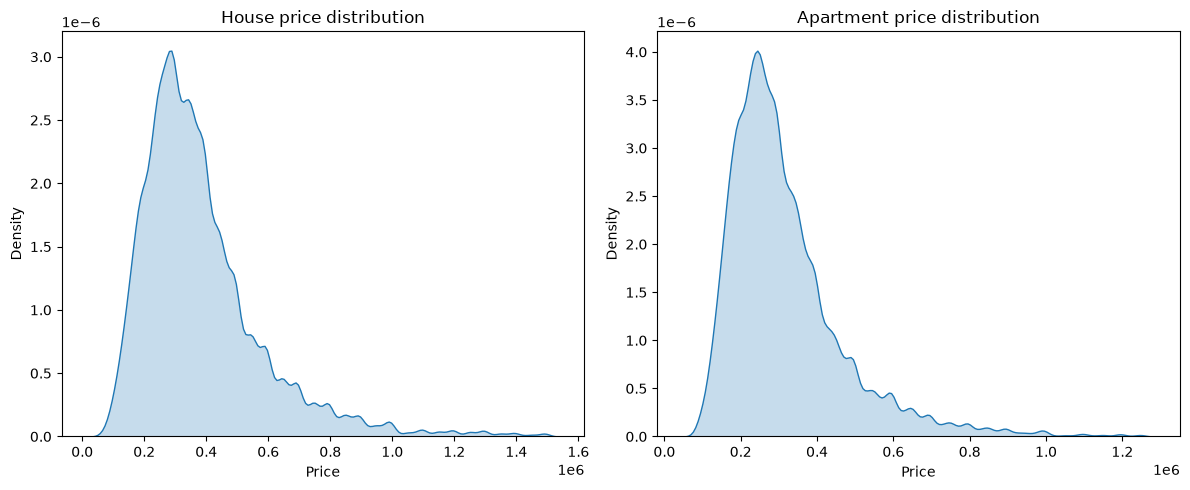

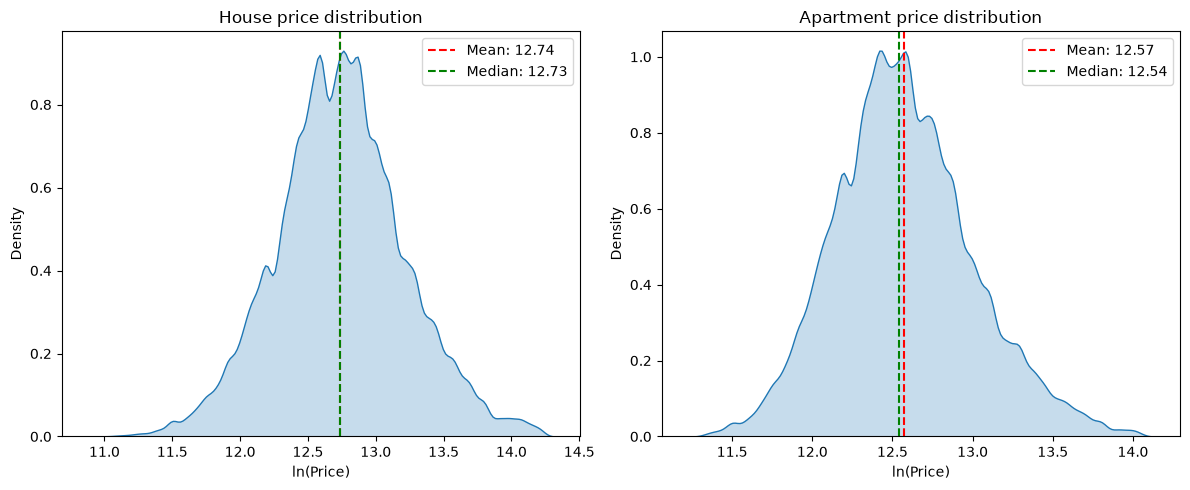

In [7]:
# ---------------------------------------------------------------------------
# 3. Plot price distribution
# ---------------------------------------------------------------------------

# Let's see what the distribution of 'Price' looks like for both apartments and houses
# Create a figure and two subplots (1 row, 2 columns)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot KDE for 'HOUSE' on the left subplot
sns.kdeplot(data=data_realo[data_realo['housingType'] == 'HOUSE'], x='price', ax=ax1, fill=True)
ax1.set_title('House price distribution')
ax1.set_xlabel('Price')
ax1.set_ylabel('Density')

# Plot KDE for 'APARTMENT' on the right subplot
sns.kdeplot(data=data_realo[data_realo['housingType'] == 'APARTMENT'], x='price', ax=ax2, fill=True)
ax2.set_title('Apartment price distribution')
ax2.set_xlabel('Price')
ax2.set_ylabel('Density')

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

# This data seems to be log-normally distributed. Let's do a log-transform and 
# plot again

data_realo["ln(price)"] = np.log(data_realo["price"]) 
data_realo["ln(initialPrice)"] = np.log(data_realo["initialPrice"]) 

# Create a figure and two subplots (1 row, 2 columns)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Left subplot: HOUSE 
house_data = data_realo[data_realo['housingType'] == 'HOUSE']['ln(price)']
sns.kdeplot(data=house_data, ax=ax1, fill=True)
ax1.set_title('House price distribution')
ax1.set_xlabel('ln(Price)')
ax1.set_ylabel('Density')

# Calculate mean and median for HOUSE
mean_house = house_data.mean()
median_house = house_data.median()

# Add vertical lines for mean and median
ax1.axvline(mean_house, color='red', linestyle='--', label=f'Mean: {mean_house:.2f}')
ax1.axvline(median_house, color='green', linestyle='--', label=f'Median: {median_house:.2f}')
ax1.legend()

# Right subplot: APARTMENT 
apartment_data = data_realo[data_realo['housingType'] == 'APARTMENT']['ln(price)']
sns.kdeplot(data=apartment_data, ax=ax2, fill=True)
ax2.set_title('Apartment price distribution')
ax2.set_xlabel('ln(Price)')
ax2.set_ylabel('Density')

# Calculate mean and median for APARTMENT
mean_apartment = apartment_data.mean()
median_apartment = apartment_data.median()

# Add vertical lines for mean and median
ax2.axvline(mean_apartment, color='red', linestyle='--', label=f'Mean: {mean_apartment:.2f}')
ax2.axvline(median_apartment, color='green', linestyle='--', label=f'Median: {median_apartment:.2f}')
ax2.legend()

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

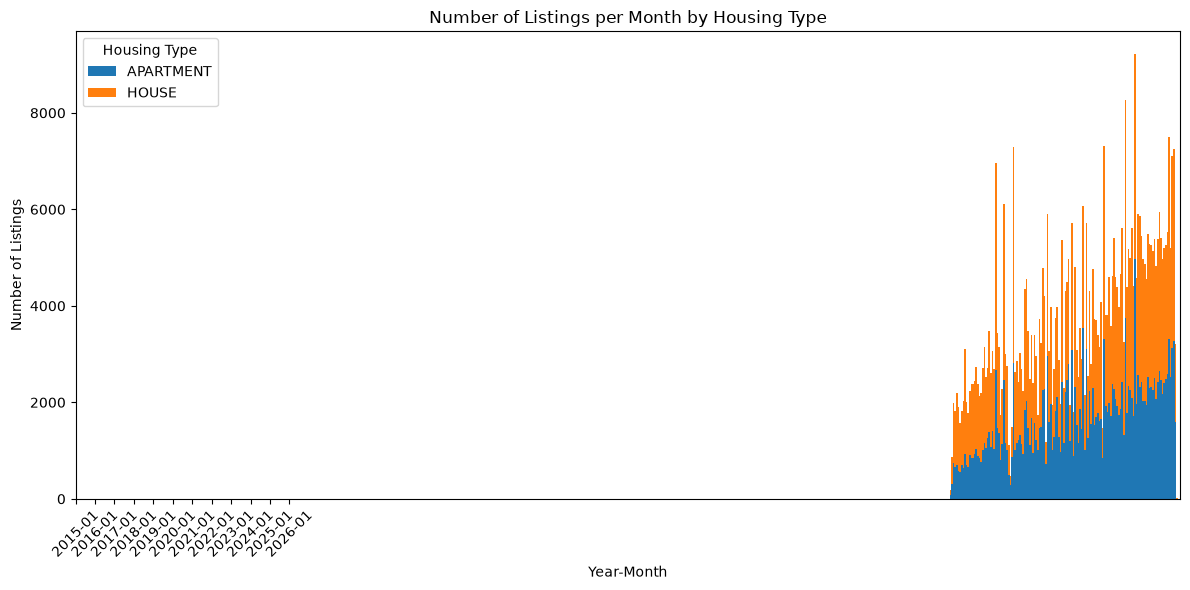

In [8]:
# ---------------------------------------------------------------------------
# 4. Plot listings
# ---------------------------------------------------------------------------

# In order to plot the number of transacties (i.e. sales) over time, we will 
# first need to extract the year and month from the 'lastListing' column

# Combine year and month into a single column
data_realo['firstListing year_month'] = data_realo['firstListing'].dt.to_period('M')
data_realo['lastListing year_month'] = data_realo['lastListing'].dt.to_period('M')

# Create a stacked bar chart to show the number of transactions every month
# I use 'lastListing' here because I will use 'price' rather than 
# 'initialPrice' later in the script

# Count observations per month and housing type
counts = data_realo.groupby(['lastListing year_month', 'housingType']).size().unstack(fill_value=0)

# Plot stacked bar chart
ax = counts.plot(kind='bar', stacked=True, figsize=(12, 6), width=1.0)

# Customize the plot
plt.title('Number of Listings per Month by Housing Type')
plt.xlabel('Year-Month')
plt.ylabel('Number of Listings')

# Rotate x-axis labels for readability
plt.xticks(rotation=45)

# Show x-axis labels only every 12 months (once per year)
x_labels = counts.index
x_ticks = ax.set_xticks(range(0, len(x_labels), 12))
ax.set_xticklabels(x_labels[::12], rotation=45)

# Ensure the plot has balanced margins and all text is visible
plt.subplots_adjust(left=0.1, right=0.9, bottom=0.2, top=0.9)

# Add legend
plt.legend(title='Housing Type')

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

# Why does the number of listings drop off at the end? -> because the data runs 
# until August 2026 yet the last observation (using "lastListing year_month")
# has an associated date in 10/2026 -> best not to use these last observations

In [9]:
# ---------------------------------------------------------------------------
# 5. Plot evolution house prices, CPI, and gross income
# ---------------------------------------------------------------------------

data_CPI = pd.read_excel("CPI index.xlsx", sheet_name="CPI")
gross_income_data = pd.read_excel("evolution.xlsx",
                                  sheet_name= "NUTS3")

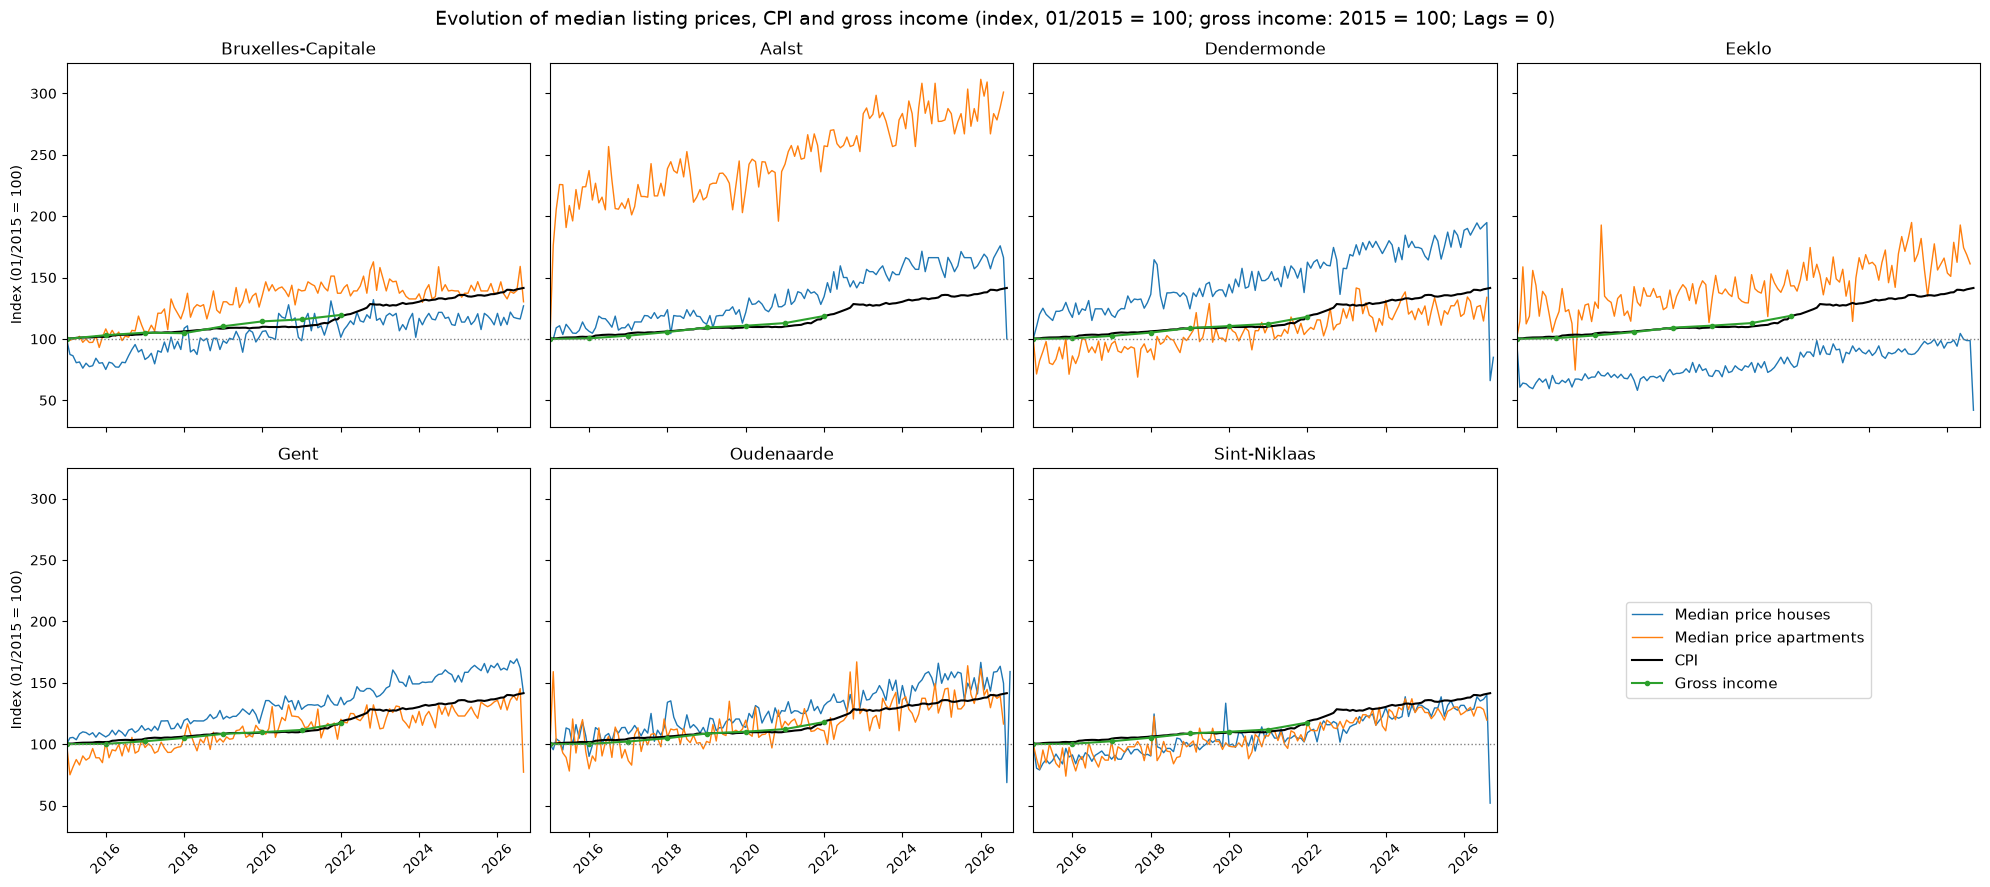

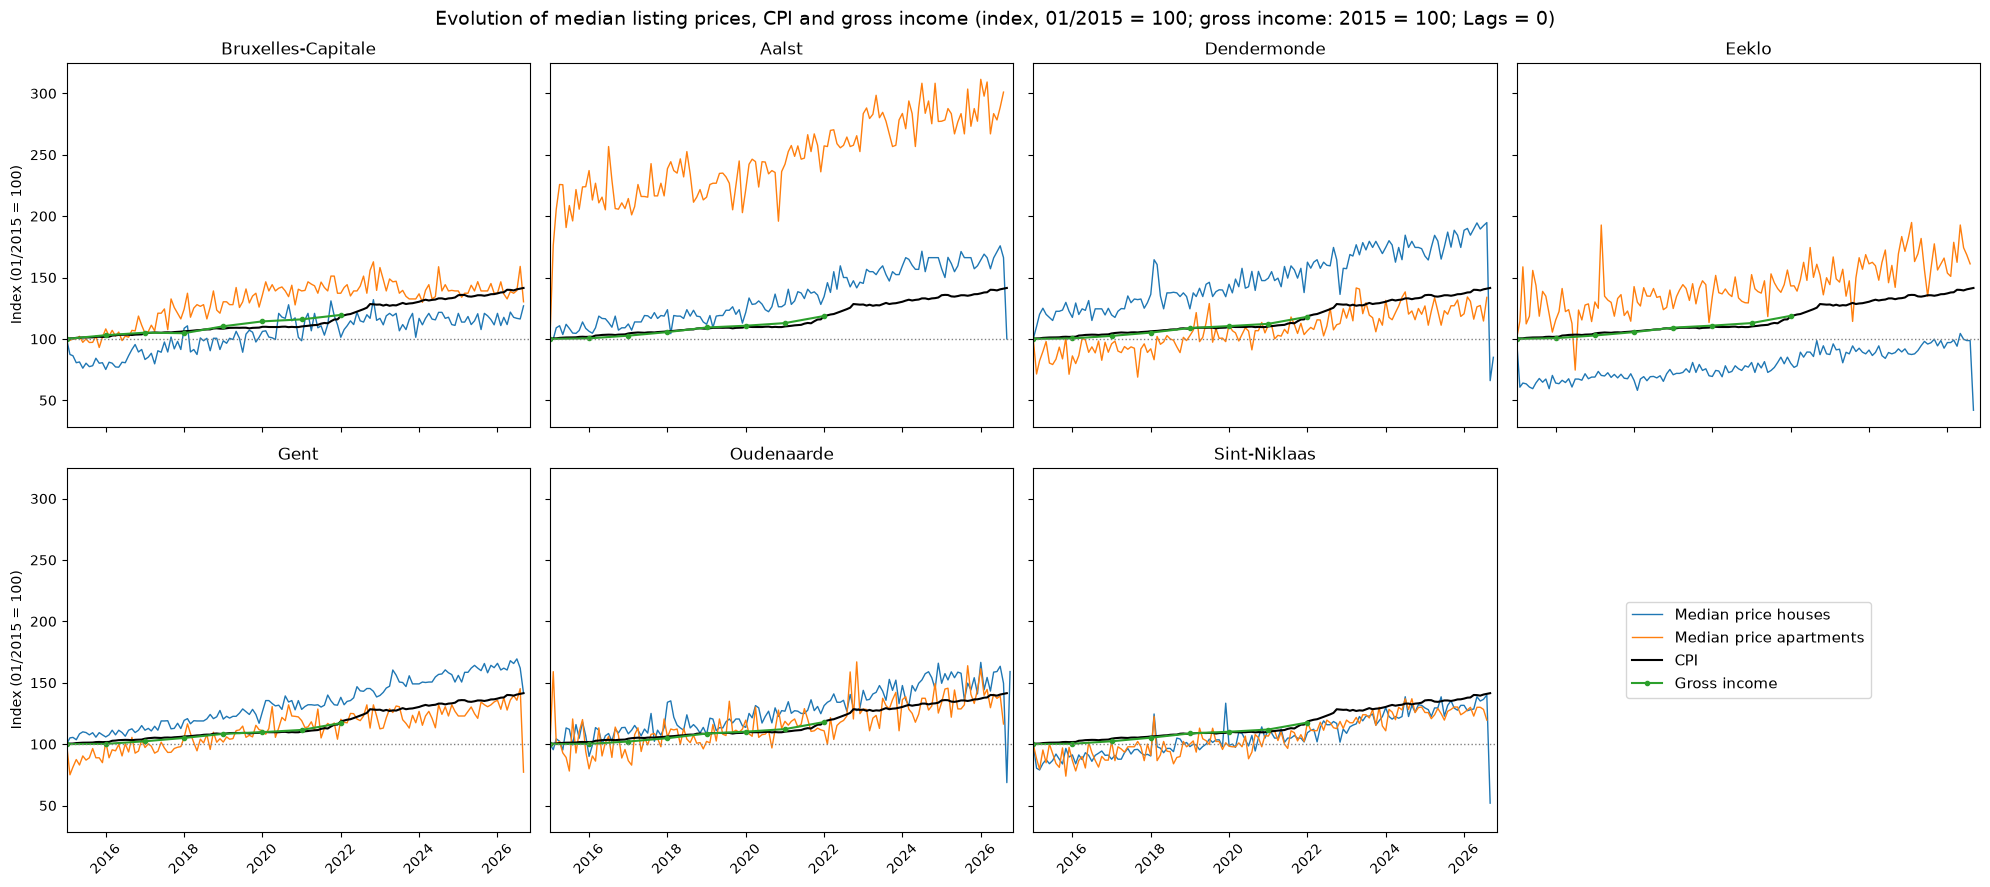

In [10]:
# --- Function: plot the evolution of house prices, CPI and gross income -----

def plot_index_evolution(data_prices=data_realo, data_CPI=data_CPI,
                         data_income=gross_income_data,
                         start_date="01/2015", end_date="08/2026", Lags=0):
    """
    Plot, per admin2 region, the indexed evolution (start_date = 100) of the
    median listing price of houses and apartments, the CPI and gross income.

    Parameters
    ----------
    data_prices : DataFrame with 'admin2', 'housingType',
                  'lastListing year_month' and 'price'.
    data_CPI    : DataFrame with 'Date' ("MM/YYYY" or datetime) and 'CPI index'.
    data_income : DataFrame with 'Abbreviated name' and one column per year.
    start_date  : base month and first month shown, "MM/YYYY".
    end_date    : last month shown, "MM/YYYY".
    Lags        : number of lags used for the price series ONLY. The price
                  in month t is the median of all listings in months
                  t-Lags, ..., t (pooled). Lags = 0 -> monthly median;
                  Lags = 11 -> 12 months of data (t-11 up to t).

    Raises
    ------
    ValueError if the price data of a region/housing type does not reach back
    to start_date - Lags, or if the CPI or gross income data do not contain
    the base period.
    """

    # --- Check and convert the arguments ------------------------------------
    if not isinstance(Lags, int) or Lags < 0:
        raise ValueError("Lags must be a non-negative integer.")
    start = pd.Period(pd.to_datetime(start_date, format="%m/%Y"), freq="M")
    end = pd.Period(pd.to_datetime(end_date, format="%m/%Y"), freq="M")
    if start > end:
        raise ValueError("start_date must be before end_date.")
    first_needed = start - Lags   # first month needed for the lagged series
    months = pd.period_range(start, end, freq="M")

    # Work on copies so that the original dataframes are not modified
    data_prices = data_prices.copy()
    data_CPI = data_CPI.copy()
    data_income = data_income.copy()

    # --- CPI: convert 'Date' ("MM/YYYY") to datetime --------------------------
    if not pd.api.types.is_datetime64_any_dtype(data_CPI["Date"]):
        data_CPI["Date"] = pd.to_datetime(data_CPI["Date"].astype(str),
                                          format="%m/%Y")
    cpi = data_CPI.set_index(data_CPI["Date"].dt.to_period("M"))["CPI index"]
    if start not in cpi.index:
        raise ValueError(f"The CPI data has no observation for {start_date} "
                         f"(it covers {cpi.index.min()} to {cpi.index.max()}).")
    cpi_index = cpi / cpi[start] * 100
    cpi_index = cpi_index[(cpi_index.index >= start) & (cpi_index.index <= end)]

    # --- Gross income: keep the relevant regions -----------------------------
    income_regions = ["Brussels Hoofdstedelijk Gewest", "Aalst", "Dendermonde",
                      "Eeklo", "Gent", "Oudenaarde", "Sint-Niklaas"]
    data_income = data_income[data_income["Abbreviated name"].isin(income_regions)]
    income_year_cols = [c for c in data_income.columns if str(c).isdigit()]
    income = data_income.set_index("Abbreviated name")[income_year_cols]
    income.columns = income.columns.astype(int)
    if start.year not in income.columns:
        raise ValueError(f"The gross income data has no observation for "
                         f"{start.year} (it covers {min(income.columns)} to "
                         f"{max(income.columns)}).")
    income_index = income.div(income[start.year], axis=0) * 100
    income_index = income_index.loc[:, (income_index.columns >= start.year)
                                       & (income_index.columns <= end.year)]

    # Link the 'admin2' names in the Realo data to the names in the income data
    region_map = {"Bruxelles-Capitale": "Brussels Hoofdstedelijk Gewest",
                  "Aalst": "Aalst", "Dendermonde": "Dendermonde",
                  "Eeklo": "Eeklo", "Gent": "Gent", "Oudenaarde": "Oudenaarde",
                  "Sint-Niklaas": "Sint-Niklaas"}

    # --- Prices: (lagged) median price index per region and housing type ----
    data_prices = data_prices.dropna(subset=["admin2", "housingType",
                                             "lastListing year_month", "price"])

    def lagged_median_index(region, housing_type):
        """Pooled median over months t-Lags ... t, indexed to start = 100."""
        sub = data_prices[(data_prices["admin2"] == region)
                          & (data_prices["housingType"] == housing_type)]
        listing_month = sub["lastListing year_month"]
        price = sub["price"].astype(float)

        # Error if the data does not reach back far enough
        if sub.empty or listing_month.min() > first_needed:
            first_available = "none" if sub.empty else listing_month.min()
            raise ValueError(
                f"Too few datapoints for {housing_type} in {region}: with "
                f"Lags = {Lags}, data from {first_needed} onwards is needed, "
                f"but the first observation is {first_available}.")

        median = pd.Series(
            [price[(listing_month >= t - Lags) & (listing_month <= t)].median()
             for t in months],
            index=months)

        if pd.isna(median[start]):
            raise ValueError(
                f"No {housing_type} listings for {region} in the window "
                f"{first_needed} to {start}; the base value cannot be computed.")
        return median / median[start] * 100

    # --- Plot: one panel per region ------------------------------------------
    window_label = "" if Lags == 0 else f" ({Lags + 1}-month window)"

    fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharex=True, sharey=True)
    axes = axes.flatten()

    for ax, (region, income_name) in zip(axes, region_map.items()):

        # Median price index for houses and apartments
        for housing_type, label, color in [("HOUSE", "Median price houses", "tab:blue"),
                                           ("APARTMENT", "Median price apartments", "tab:orange")]:
            price_index = lagged_median_index(region, housing_type)
            ax.plot(price_index.index.to_timestamp(), price_index.values,
                    label=label + window_label, color=color, linewidth=1)

        # CPI index
        ax.plot(cpi_index.index.to_timestamp(), cpi_index.values,
                label="CPI", color="black", linewidth=1.5)

        # Gross income index, plotted in January of each year
        region_income = income_index.loc[income_name]
        income_dates = pd.to_datetime([f"{year}-01-01" for year in region_income.index])
        ax.plot(income_dates, region_income.values, label="Gross income",
                color="tab:green", marker="o", markersize=3, linewidth=1.5)

        ax.axhline(100, color="grey", linestyle=":", linewidth=1)
        ax.set_title(region)
        ax.tick_params(axis="x", rotation=45)

    # Show only the period start_date - end_date
    axes[0].set_xlim(start.to_timestamp(), end.to_timestamp(how="end"))

    # Hide the axes of the empty eighth panel (it is used for the legend below)
    for ax in axes[len(region_map):]:
        ax.axis("off")

    for ax in axes[::4]:
        ax.set_ylabel(f"Index ({start_date} = 100)")

    # One shared legend (taken from the first panel), placed inside the empty
    # eighth panel so that it cannot overlap with any of the region panels
    handles, labels = axes[0].get_legend_handles_labels()
    axes[-1].legend(handles, labels, loc="center", fontsize=11)

    fig.suptitle(f"Evolution of median listing prices, CPI and gross income "
                 f"(index, {start_date} = 100; gross income: {start.year} = 100; "
                 f"Lags = {Lags})",
                 fontsize=14)
    plt.tight_layout()
    plt.show()

    return fig


# Plot with the default settings (monthly medians, 01/2015 - 08/2026)
plot_index_evolution(end_date="10/2026")

# Plot for period 01/2017-08/2026 with lags = 11s

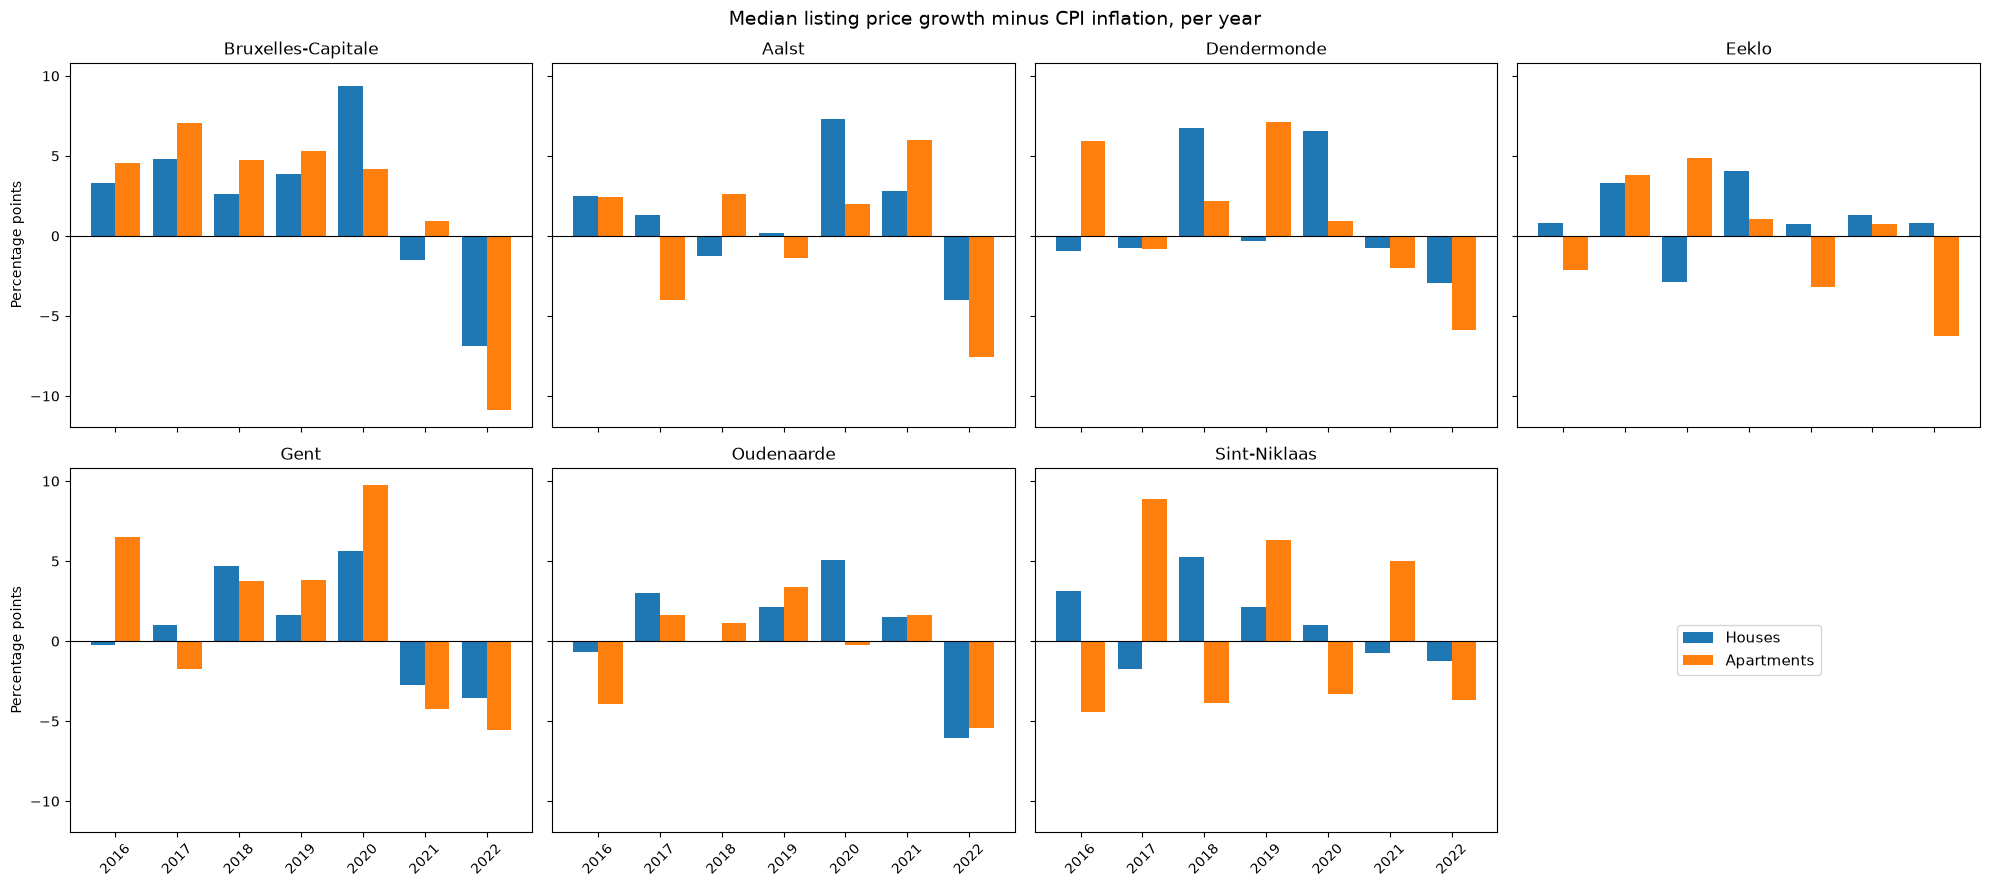

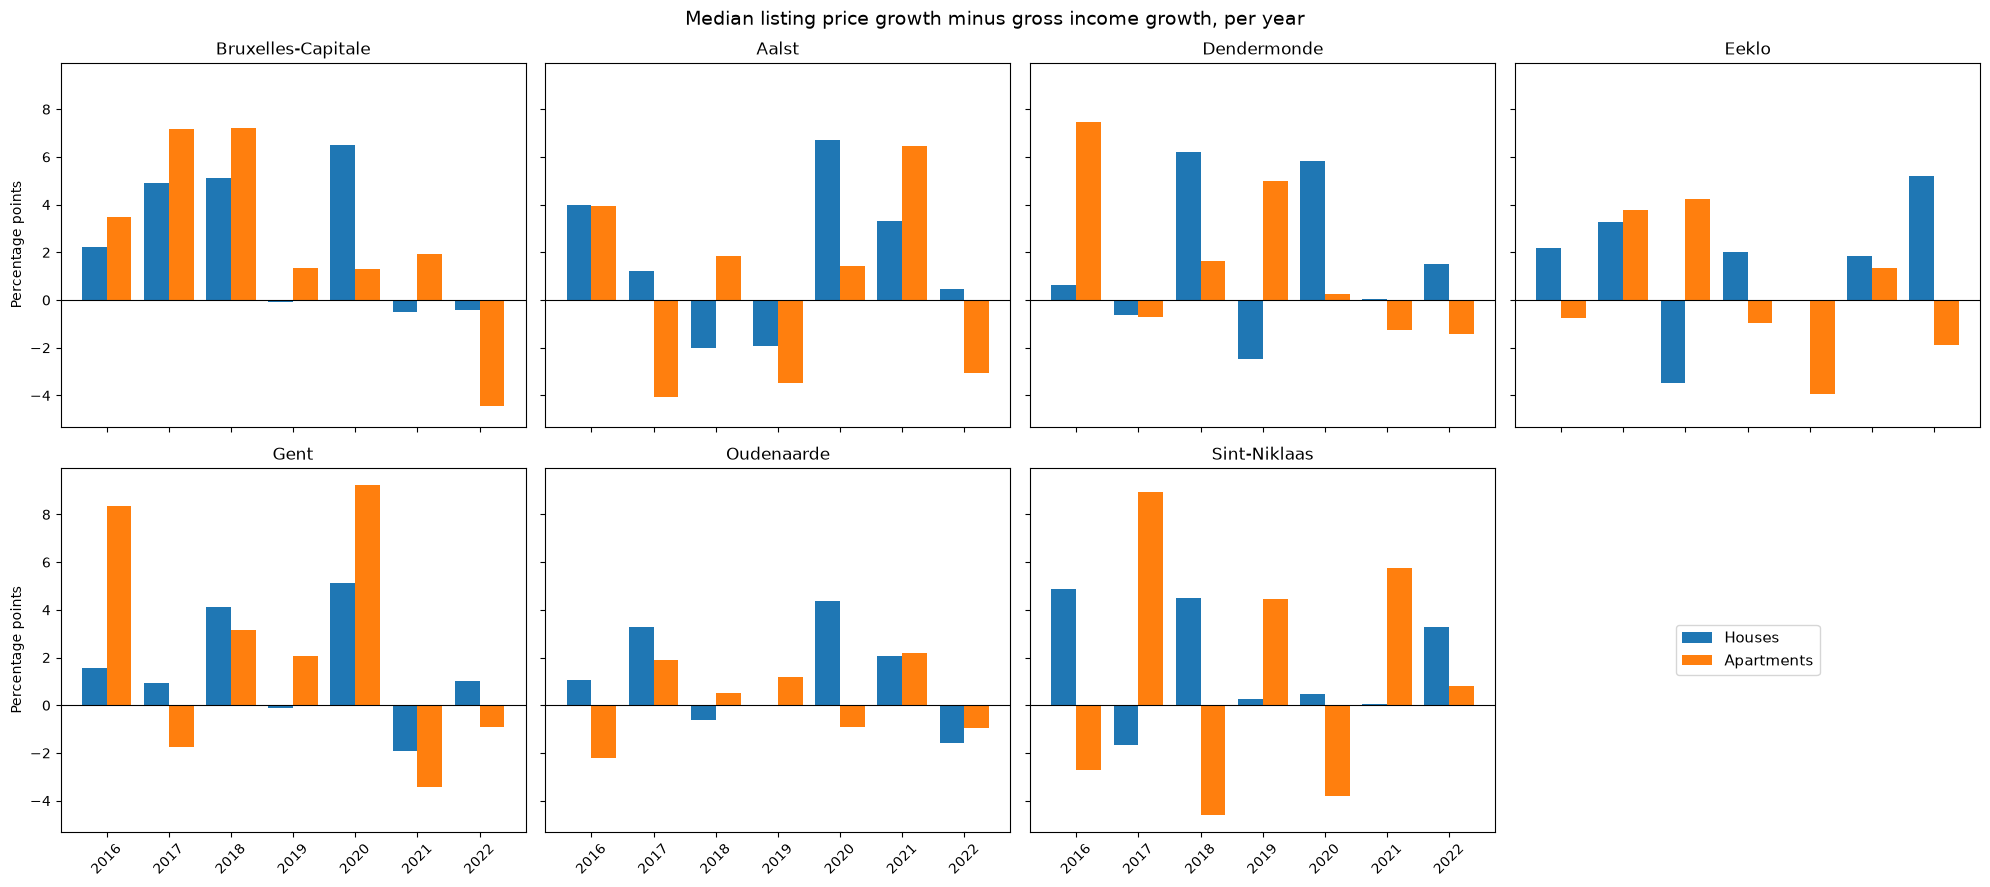


PRICE GROWTH MINUS CPI INFLATION - HOUSE (percentage points)
         Bruxelles-Capitale  Aalst  Dendermonde  Eeklo  Gent  Oudenaarde  Sint-Niklaas
2016                   +3.3   +2.5         -0.9   +0.8  -0.2        -0.7          +3.2
2017                   +4.8   +1.3         -0.7   +3.3  +1.0        +3.0          -1.7
2018                   +2.6   -1.2         +6.7   -2.8  +4.7        -0.0          +5.3
2019                   +3.9   +0.2         -0.3   +4.0  +1.6        +2.2          +2.1
2020                   +9.4   +7.3         +6.5   +0.7  +5.6        +5.1          +1.0
2021                   -1.5   +2.8         -0.7   +1.3  -2.7        +1.5          -0.7
2022                   -6.9   -4.0         -2.9   +0.8  -3.6        -6.1          -1.2
Average                +2.2   +1.3         +1.1   +1.2  +0.9        +0.7          +1.1

PRICE GROWTH MINUS CPI INFLATION - APARTMENT (percentage points)
         Bruxelles-Capitale  Aalst  Dendermonde  Eeklo  Gent  Oudenaarde  Sint-Niklaas
20

In [11]:
# ---------------------------------------------------------------------------
# 6. Yearly gaps: house prices vs CPI, and house prices vs gross income
# ---------------------------------------------------------------------------
# Run this after the cells above: it uses data_realo, data_CPI and
# gross_income_data.
#
# Definitions (per year, in percentage points):
#   gap vs CPI    = growth of the median listing price - CPI inflation
#   gap vs income = growth of the median listing price - growth of gross income
# Growth in year t is the change compared with year t-1.
# A gap of +3 means prices grew 3 percentage points faster than CPI (or than
# gross income) that year; -3 means they grew 3 points slower.
#
# Price = median listing price of the listings whose 'lastListing' falls in
# that year. CPI = average of the monthly CPI values in that year.

region_map = {"Bruxelles-Capitale": "Brussels Hoofdstedelijk Gewest",
              "Aalst": "Aalst", "Dendermonde": "Dendermonde",
              "Eeklo": "Eeklo", "Gent": "Gent", "Oudenaarde": "Oudenaarde",
              "Sint-Niklaas": "Sint-Niklaas"}
housing_types = ["HOUSE", "APARTMENT"]


def compute_yearly_gaps(data_prices=data_realo, data_CPI=data_CPI,
                        data_income=gross_income_data,
                        first_year=2015, last_year=2025):
    """
    Compute, per region and housing type, the yearly gap (in percentage
    points) between house price growth and (a) CPI inflation, (b) gross
    income growth.

    Parameters
    ----------
    first_year : base year; the first gap is reported for first_year + 1.
    last_year  : last year included. Use a full year (the data for the most
                 recent year is incomplete).

    Returns
    -------
    gaps_cpi, gaps_income : dicts {housing type: DataFrame}, each DataFrame
        with the years as rows and the regions as columns.
    """
    years = list(range(first_year, last_year + 1))

    # --- CPI: yearly average, then yearly inflation in % --------------------
    cpi = data_CPI.copy()
    if not pd.api.types.is_datetime64_any_dtype(cpi["Date"]):
        cpi["Date"] = pd.to_datetime(cpi["Date"].astype(str), format="%m/%Y")
    cpi_year = cpi.groupby(cpi["Date"].dt.year)["CPI index"].mean()
    missing = [y for y in years if y not in cpi_year.index]
    if missing:
        raise ValueError(f"The CPI data does not cover year(s) {missing}.")
    cpi_year = cpi_year.loc[years].astype(float)
    cpi_growth = (cpi_year / cpi_year.shift(1) - 1) * 100

    # --- Gross income: yearly growth in % per region ------------------------
    inc = data_income[data_income["Abbreviated name"].isin(region_map.values())]
    year_cols = [c for c in inc.columns if str(c).isdigit()]
    inc = inc.set_index("Abbreviated name")[year_cols]
    inc.columns = inc.columns.astype(int)
    missing = [y for y in years if y not in inc.columns]
    if missing:
        raise ValueError(f"The gross income data does not cover year(s) "
                         f"{missing} (it covers {min(inc.columns)} to "
                         f"{max(inc.columns)}). Lower last_year.")
    inc = inc[years].astype(float)
    inc_growth = (inc / inc.shift(1, axis=1) - 1) * 100

    # --- Prices: yearly median listing price per region and housing type ----
    p = data_prices.dropna(subset=["admin2", "housingType",
                                   "lastListing", "price"]).copy()
    p["admin2"] = p["admin2"].astype(str)
    p["housingType"] = p["housingType"].astype(str)
    p["price"] = p["price"].astype(float)
    p["year"] = p["lastListing"].dt.year
    median = (p.groupby(["admin2", "housingType", "year"])["price"].median()
                .unstack("year").reindex(columns=years))

    # --- Gaps ----------------------------------------------------------------
    gaps_cpi = {}
    gaps_income = {}
    for housing_type in housing_types:
        vs_cpi = {}
        vs_income = {}
        for region, income_name in region_map.items():
            if (region, housing_type) not in median.index:
                raise ValueError(f"No {housing_type} listings for {region}.")
            price = median.loc[(region, housing_type)]
            if price.isna().any():
                no_data = [y for y in years if pd.isna(price[y])]
                raise ValueError(f"No {housing_type} listings for {region} "
                                 f"in year(s) {no_data}.")
            price_growth = (price / price.shift(1) - 1) * 100
            vs_cpi[region] = price_growth - cpi_growth
            vs_income[region] = price_growth - inc_growth.loc[income_name]
        gaps_cpi[housing_type] = pd.DataFrame(vs_cpi).iloc[1:]
        gaps_income[housing_type] = pd.DataFrame(vs_income).iloc[1:]
        gaps_cpi[housing_type].index.name = "Year"
        gaps_income[housing_type].index.name = "Year"

    return gaps_cpi, gaps_income


def plot_yearly_gaps(gaps, title, ylabel):
    """One panel per region: yearly gap for houses and apartments (bars)."""
    years = list(gaps["HOUSE"].index)
    x = np.arange(len(years))
    width = 0.4

    fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharex=True, sharey=True)
    axes = axes.flatten()

    for ax, region in zip(axes, region_map):
        ax.bar(x - width / 2, gaps["HOUSE"][region].values, width,
               label="Houses", color="tab:blue")
        ax.bar(x + width / 2, gaps["APARTMENT"][region].values, width,
               label="Apartments", color="tab:orange")
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_title(region)
        ax.set_xticks(x)
        ax.set_xticklabels(years, rotation=45)

    # Hide the empty eighth panel and use it for the legend
    for ax in axes[len(region_map):]:
        ax.axis("off")
    handles, labels = axes[0].get_legend_handles_labels()
    axes[-1].legend(handles, labels, loc="center", fontsize=11)

    for ax in axes[::4]:
        ax.set_ylabel(ylabel)

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()
    return fig


def print_gap_tables(gaps, title):
    """Print one table per housing type: rows = years, columns = regions."""
    for housing_type in housing_types:
        table = gaps[housing_type]
        table = pd.concat([table, table.mean().to_frame("Average").T])
        print("\n" + "=" * 70)
        print(f"{title} - {housing_type} (percentage points)")
        print("=" * 70)
        print(table.to_string(float_format=lambda v: f"{v:+.1f}"))


# --- Run ---------------------------------------------------------------------
# Years 2016-2025 (2015 is the base year; 2026 is left out because it is
# incomplete). Change first_year / last_year if you want another period.
gaps_cpi, gaps_income = compute_yearly_gaps(first_year=2015, last_year=2022)

plot_yearly_gaps(gaps_cpi,
                 "Median listing price growth minus CPI inflation, per year",
                 "Percentage points")
plot_yearly_gaps(gaps_income,
                 "Median listing price growth minus gross income growth, "
                 "per year",
                 "Percentage points")

print_gap_tables(gaps_cpi, "PRICE GROWTH MINUS CPI INFLATION")
print_gap_tables(gaps_income, "PRICE GROWTH MINUS GROSS INCOME GROWTH")

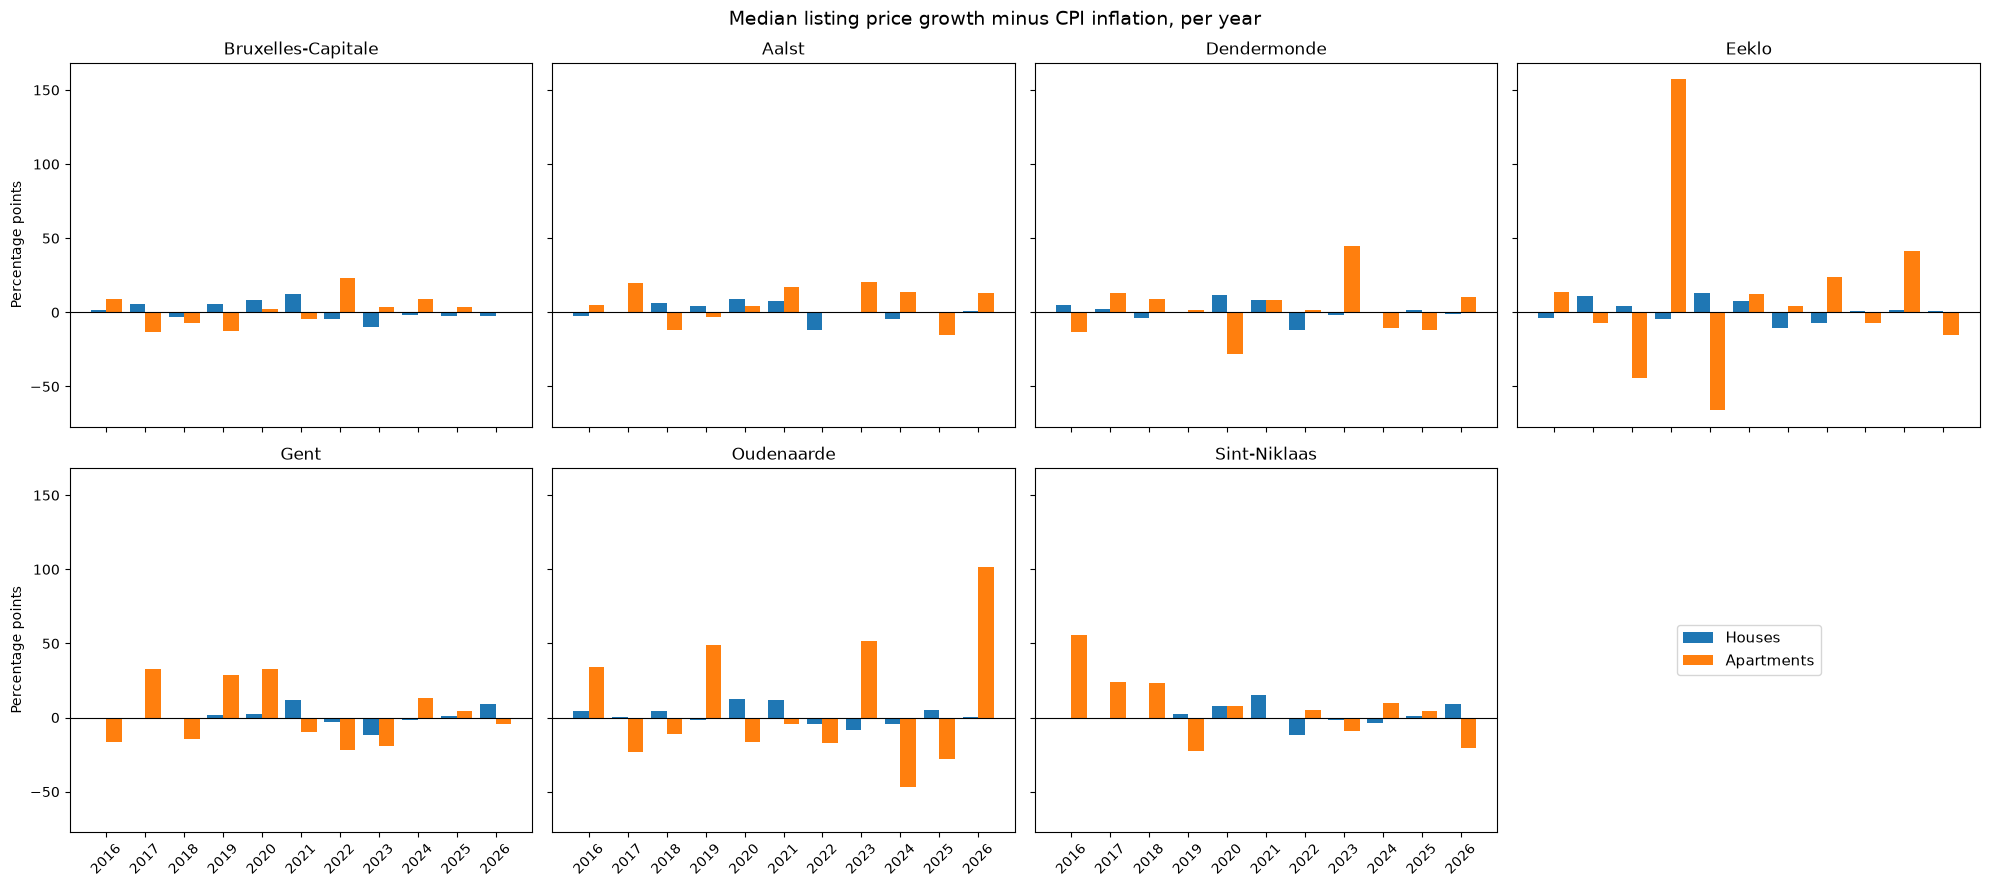


PRICE GROWTH MINUS CPI INFLATION - HOUSE (percentage points)
         Bruxelles-Capitale  Aalst  Dendermonde  Eeklo  Gent  Oudenaarde  Sint-Niklaas
2016                   +1.3   -2.6         +5.2   -3.8  +0.0        +4.6          -0.6
2017                   +5.5   +0.5         +2.1  +10.8  +0.0        +0.4          -1.0
2018                   -3.1   +6.5         -3.9   +4.2  -0.6        +4.6          -0.1
2019                   +5.8   +4.2         -0.1   -4.5  +2.1        -1.7          +2.5
2020                   +8.3   +9.2        +11.8  +13.2  +2.5       +12.7          +7.5
2021                  +12.7   +7.3         +8.5   +7.7 +11.6       +11.8         +15.2
2022                   -4.5  -11.8        -11.6  -10.3  -3.0        -4.2         -12.0
2023                   -9.5   +0.0         -1.9   -7.4 -11.5        -8.7          -1.8
2024                   -2.0   -4.2         +0.2   +0.8  -1.6        -4.4          -3.6
2025                   -2.7   +0.4         +1.5   +1.9  +1.0        

In [12]:
# ---------------------------------------------------------------------------
# 6. Yearly gaps: house prices vs CPI, and house prices vs gross income
# ---------------------------------------------------------------------------
# Run this after the cells above: it uses data_realo, data_CPI and
# gross_income_data.
#
# Definitions (per year, in percentage points):
#   gap vs CPI    = growth of the median listing price - CPI inflation
#   gap vs income = growth of the median listing price - growth of gross income
# Growth in year t is the change compared with year t-1.
# A gap of +3 means prices grew 3 percentage points faster than CPI (or than
# gross income) that year; -3 means they grew 3 points slower.
#
# Price = median listing price of the listings whose 'lastListing' falls in
# that year. CPI = average of the monthly CPI values in that year.

region_map = {"Bruxelles-Capitale": "Brussels Hoofdstedelijk Gewest",
              "Aalst": "Aalst", "Dendermonde": "Dendermonde",
              "Eeklo": "Eeklo", "Gent": "Gent", "Oudenaarde": "Oudenaarde",
              "Sint-Niklaas": "Sint-Niklaas"}
housing_types = ["HOUSE", "APARTMENT"]


def compute_yearly_gaps(data_prices=data_realo, data_CPI=data_CPI,
                        first_year=2015, last_year=2025):
    """
    Compute, per region and housing type, the yearly gap (in percentage
    points) between house price growth and (a) CPI inflation, (b) gross
    income growth.

    Parameters
    ----------
    first_year : base year; the first gap is reported for first_year + 1.
    last_year  : last year included. Use a full year (the data for the most
                 recent year is incomplete).

    Returns
    -------
    gaps_cpi, gaps_income : dicts {housing type: DataFrame}, each DataFrame
        with the years as rows and the regions as columns.
    """
    data_prices = data_prices[data_prices["estimatedArea"]!= np.nan]
    data_prices["price/m2"] = data_prices["price"] / data_prices["estimatedArea"]
    
    

    years = list(range(first_year, last_year + 1))

    # --- CPI: yearly average, then yearly inflation in % --------------------
    cpi = data_CPI.copy()
    if not pd.api.types.is_datetime64_any_dtype(cpi["Date"]):
        cpi["Date"] = pd.to_datetime(cpi["Date"].astype(str), format="%m/%Y")
    cpi_year = cpi.groupby(cpi["Date"].dt.year)["CPI index"].mean()
    missing = [y for y in years if y not in cpi_year.index]
    if missing:
        raise ValueError(f"The CPI data does not cover year(s) {missing}.")
    cpi_year = cpi_year.loc[years].astype(float)
    cpi_growth = (cpi_year / cpi_year.shift(1) - 1) * 100

   

    # --- Prices: yearly median listing price per region and housing type ----
    p = data_prices.dropna(subset=["admin2", "housingType",
                                   "lastListing", "price/m2"]).copy()
    p["admin2"] = p["admin2"].astype(str)
    p["housingType"] = p["housingType"].astype(str)
    p["price/m2"] = p["price/m2"].astype(float)
    p["year"] = p["lastListing"].dt.year
    median = (p.groupby(["admin2", "housingType", "year"])["price/m2"].median()
                .unstack("year").reindex(columns=years))

    # --- Gaps ----------------------------------------------------------------
    gaps_cpi = {}
    
    for housing_type in housing_types:
        vs_cpi = {}
        for region, income_name in region_map.items():
            if (region, housing_type) not in median.index:
                raise ValueError(f"No {housing_type} listings for {region}.")
            price = median.loc[(region, housing_type)]
            if price.isna().any():
                no_data = [y for y in years if pd.isna(price[y])]
                raise ValueError(f"No {housing_type} listings for {region} "
                                 f"in year(s) {no_data}.")
            price_growth = (price / price.shift(1) - 1) * 100
            vs_cpi[region] = price_growth - cpi_growth
        gaps_cpi[housing_type] = pd.DataFrame(vs_cpi).iloc[1:]
        gaps_cpi[housing_type].index.name = "Year"

    return gaps_cpi


def plot_yearly_gaps(gaps, title, ylabel):
    """One panel per region: yearly gap for houses and apartments (bars)."""
    years = list(gaps["HOUSE"].index)
    x = np.arange(len(years))
    width = 0.4

    fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharex=True, sharey=True)
    axes = axes.flatten()

    for ax, region in zip(axes, region_map):
        ax.bar(x - width / 2, gaps["HOUSE"][region].values, width,
               label="Houses", color="tab:blue")
        ax.bar(x + width / 2, gaps["APARTMENT"][region].values, width,
               label="Apartments", color="tab:orange")
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_title(region)
        ax.set_xticks(x)
        ax.set_xticklabels(years, rotation=45)

    # Hide the empty eighth panel and use it for the legend
    for ax in axes[len(region_map):]:
        ax.axis("off")
    handles, labels = axes[0].get_legend_handles_labels()
    axes[-1].legend(handles, labels, loc="center", fontsize=11)

    for ax in axes[::4]:
        ax.set_ylabel(ylabel)

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()
    return fig


def print_gap_tables(gaps, title):
    """Print one table per housing type: rows = years, columns = regions."""
    for housing_type in housing_types:
        table = gaps[housing_type]
        table = pd.concat([table, table.mean().to_frame("Average").T])
        print("\n" + "=" * 70)
        print(f"{title} - {housing_type} (percentage points)")
        print("=" * 70)
        print(table.to_string(float_format=lambda v: f"{v:+.1f}"))


# --- Run ---------------------------------------------------------------------
# Years 2016-2025 (2015 is the base year; 2026 is left out because it is
# incomplete). Change first_year / last_year if you want another period.
gaps_cpi = compute_yearly_gaps(data_prices = data_realo.copy(), first_year=2015, last_year=2026)
plot_yearly_gaps(gaps_cpi,
                 "Median listing price growth minus CPI inflation, per year",
                 "Percentage points")


print_gap_tables(gaps_cpi, "PRICE GROWTH MINUS CPI INFLATION")


In [32]:
import matplotlib.pyplot as plt

#Algemene plotfunctie met optionele jaarlijkse percentiel-buckets
def plot_data(
    data,
    x,
    y,
    split_by=None,
    agg="mean",
    freq=None,
    where=None,
    kind="line",
    bins=None,
    labels=None,
    title=None,
    xlabel=None,
    ylabel=None,
    figsize=(11, 6),
    bucket_by_year=False,
    bucket_col="price/m2",
    bucket_labels=None,
    bucket_percentiles=None,
):
    """
    General-purpose plotting function with optional yearly percentile buckets.

    Parameters
    ----------
    data : DataFrame
        Input dataset.
    x, y : str
        Columns for the axes.
        Special y values: 'price/m2', 'growth'.
    split_by : str, optional
        Column used to create separate series.
        Use 'yearly_bucket' to plot yearly percentile buckets.
    agg : str or None
        'mean', 'median', 'sum', 'count', or None.
    freq : str, optional
        Time frequency, e.g. 'M', 'Q', 'Y'.
    where : dict, optional
        Filters, e.g. {'housingType': 'HOUSE'}.
    kind : str
        'line', 'scatter', or 'bar'.
    bucket_by_year : bool
        If True, classify observations into percentile buckets
        calculated separately for each year.
    bucket_col : str
        Column used to determine percentile rank.
    bucket_labels : list, optional
        Names for the percentile buckets.
    bucket_percentiles : list, optional
        Upper percentile limits, e.g. [0.75, 0.90, 0.99, 1.0].

    Returns
    -------
    fig : matplotlib Figure
    """

    df = data.copy()

    # Apply filters
    if where:
        for col, value in where.items():
            if isinstance(value, (list, tuple, set)):
                df = df[df[col].isin(value)]
            else:
                df = df[df[col] == value]

    # Calculate price per square metre if needed
    if (
        x== "price/m2"
        or
        y == "price/m2"
        or bucket_col == "price/m2"
        or split_by == "price/m2"
    ):
        if "price/m2" not in df.columns:
            price = pd.to_numeric(df["price"], errors="coerce")
            area = pd.to_numeric(
                df["estimatedArea"], errors="coerce"
            )
            df["price/m2"] = (price / area).where(area > 0)

    # Convert the x column to dates if appropriate
    date_axis = (
        pd.api.types.is_datetime64_any_dtype(df[x])
        or any(word in x.lower() for word in ["date", "time"])
    )

    if date_axis:
        df[x] = pd.to_datetime(df[x], errors="coerce")

    # Determine the year used for yearly buckets
    if bucket_by_year:
        if date_axis:
            df["_bucket_year"] = df[x].dt.year
        elif x.lower() == "year":
            df["_bucket_year"] = pd.to_numeric(
                df[x], errors="coerce"
            )
        else:
            raise ValueError(
                "Yearly buckets require a date x column "
                "or x='year'."
            )

        # Default percentile boundaries
        if bucket_percentiles is None:
            bucket_percentiles = [0.75, 0.90, 0.99, 1.0]

        if bucket_labels is None:
            bucket_labels = [
                "Bottom 75%",
                "75–90%",
                "90–99%",
                "Top 1%",
            ]

        if len(bucket_labels) != len(bucket_percentiles):
            raise ValueError(
                "bucket_labels and bucket_percentiles "
                "must have the same length."
            )

        if (
            any(
                not 0 < p <= 1
                for p in bucket_percentiles
            )
            or sorted(bucket_percentiles) != bucket_percentiles
            or bucket_percentiles[-1] != 1.0
        ):
            raise ValueError(
                "Percentile boundaries must be increasing, "
                "between 0 and 1, and end at 1.0."
            )

        # Rank each observation within its year
        df["_bucket_value"] = pd.to_numeric(
            df[bucket_col], errors="coerce"
        )

        df = df.dropna(
            subset=["_bucket_year", "_bucket_value"]
        )

        df["_percentile"] = df.groupby(
            "_bucket_year"
        )["_bucket_value"].rank(
            pct=True, method="average"
        )

        # Convert percentile ranks into named buckets
        boundaries = [0] + bucket_percentiles

        df["yearly_bucket"] = pd.cut(
            df["_percentile"],
            bins=boundaries,
            labels=bucket_labels,
            include_lowest=True,
            right=True,
        )

        if split_by == "yearly_bucket":
            split_by = "yearly_bucket"

    # Calculate percentage growth if requested
    if y == "growth":
        if "price" not in df.columns:
            raise ValueError(
                "y='growth' requires a 'price' column."
            )

        df[y] = pd.to_numeric(df["price"], errors="coerce")

    elif y not in df.columns:
        raise ValueError(f"Column '{y}' not found.")

    df[y] = pd.to_numeric(df[y], errors="coerce")
    df = df.dropna(subset=[x, y])

    # Sort before any growth calculation
    df = df.sort_values(x)

    # Growth is calculated on the aggregated series below
    if y == "growth":
        y_source = "price"
    else:
        y_source = y

    # Prepare data for aggregation
    if freq is not None:
        df = df.set_index(x).sort_index()

        if split_by:
            grouped = df.groupby(
                split_by, observed=True
            )[y_source].resample(freq)
        else:
            grouped = df[y_source].resample(freq)

        if agg == "median":
            result = grouped.median()
        elif agg == "sum":
            result = grouped.sum()
        elif agg == "count":
            result = grouped.count()
        elif agg == "mean":
            result = grouped.mean()
        elif agg is None:
            raise ValueError(
                "Choose an aggregation when using freq."
            )
        else:
            raise ValueError(
                "agg must be mean, median, sum, count, or None."
            )

        if split_by:
            result = result.unstack(0)
        else:
            result = result.to_frame(y_source)

        # Calculate growth from the aggregated values
        if y == "growth":
            result = result.pct_change() * 100
            result.columns.name = None

        grouped_data = result

    elif agg is not None:
        group_cols = [x] + ([split_by] if split_by else [])
        grouped = df.groupby(
            group_cols, observed=True
        )[y_source]

        if agg == "median":
            result = grouped.median()
        elif agg == "sum":
            result = grouped.sum()
        elif agg == "count":
            result = grouped.count()
        elif agg == "mean":
            result = grouped.mean()
        else:
            raise ValueError(
                "agg must be mean, median, sum, count, or None."
            )

        if split_by:
            result = result.unstack(split_by)

        if y == "growth":
            if split_by:
                result = result.pct_change() * 100
            else:
                result = result.pct_change() * 100

        grouped_data = result

    else:
        # Plot individual observations without aggregation
        grouped_data = None

    # Plot
    if grouped_data is not None:
        if kind == "bar":
            ax = grouped_data.plot(
                kind="bar", figsize=figsize, rot=45
            )
        elif kind == "scatter":
            fig, ax = plt.subplots(figsize=figsize)
            if isinstance(grouped_data, pd.DataFrame):
                for col in grouped_data.columns:
                    ax.scatter(
                        grouped_data.index,
                        grouped_data[col],
                        label=str(col),
                        alpha=0.7,
                    )
                ax.legend()
            else:
                ax.scatter(
                    grouped_data.index,
                    grouped_data,
                    alpha=0.7,
                )
        else:
            ax = grouped_data.plot(
                kind="line",
                figsize=figsize,
                marker="o",
            )

        fig = ax.figure

    else:
        fig, ax = plt.subplots(figsize=figsize)

        if split_by:
            for name, group in df.groupby(
                split_by, observed=True
            ):
                ax.scatter(
                    group[x], group[y],
                    label=str(name), alpha=0.6
                ) if kind == "scatter" else ax.plot(
                    group[x], group[y],
                    label=str(name) 
                )

            ax.legend()
        elif kind == "scatter":
            ax.scatter(df[x], df[y], alpha=0.6)
        else:
            ax.plot(df[x], df[y])

    ax.set_title(title or f"{y} vs {x}")
    ax.set_xlabel(xlabel or x)
    ax.set_ylabel(
        ylabel or (
            "Growth (%)" if y == "growth" else y
        )
    )
    ax.legend(title=str(split_by[0])+ ' ' + str(bucket_col) or None)
    ax.grid(True, alpha=0.3)
    

    plt.tight_layout()
    plt.show()

    return fig


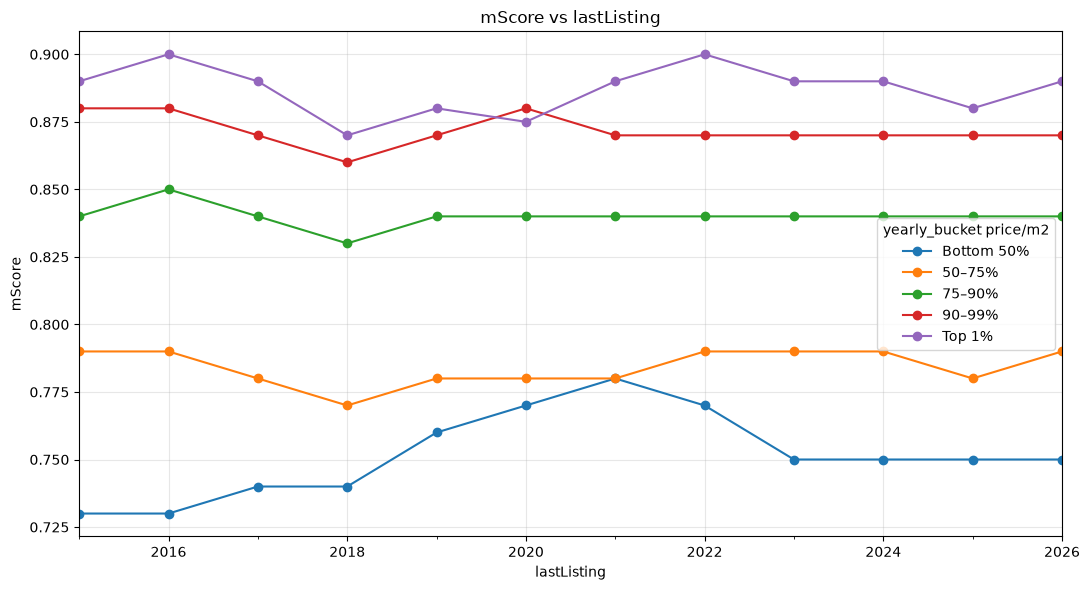

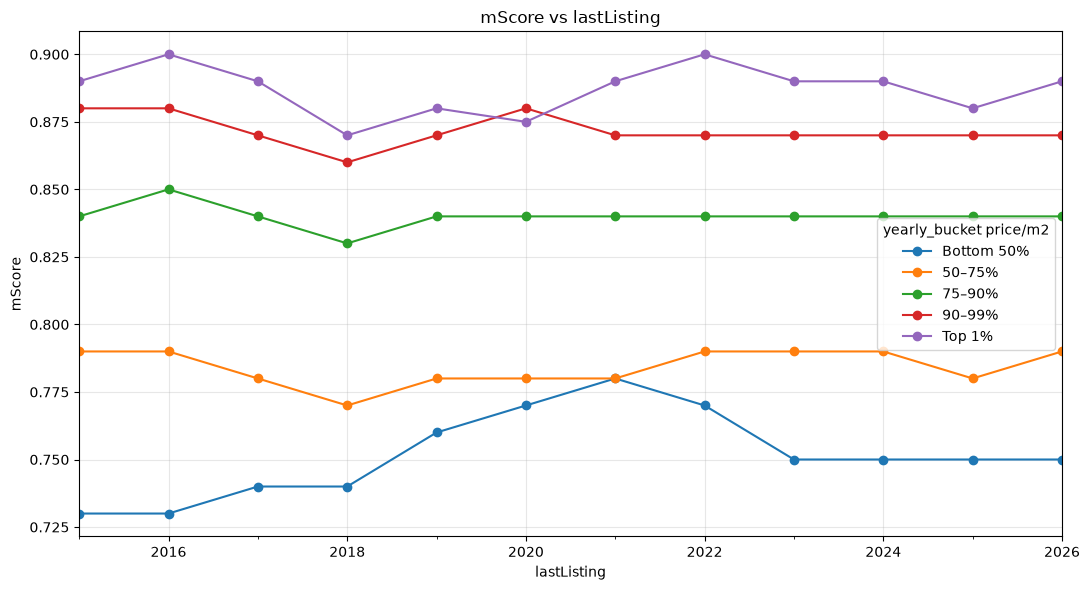

In [34]:
plot_data(
    data=data_realo,
    x="lastListing",
    y="mScore",
    bucket_col = "price/m2",
    split_by=["yearly_bucket"],
    bucket_by_year=True,
    bucket_percentiles=[0.50, 0.75, 0.90, 0.99, 1.0],
    bucket_labels=[
        "Bottom 50%",
        "50–75%",
        "75–90%",
        "90–99%",
        "Top 1%",
    ],
    
    agg="median",
    #where={"housingType": "APARTMENT"},
    freq="YE",
)

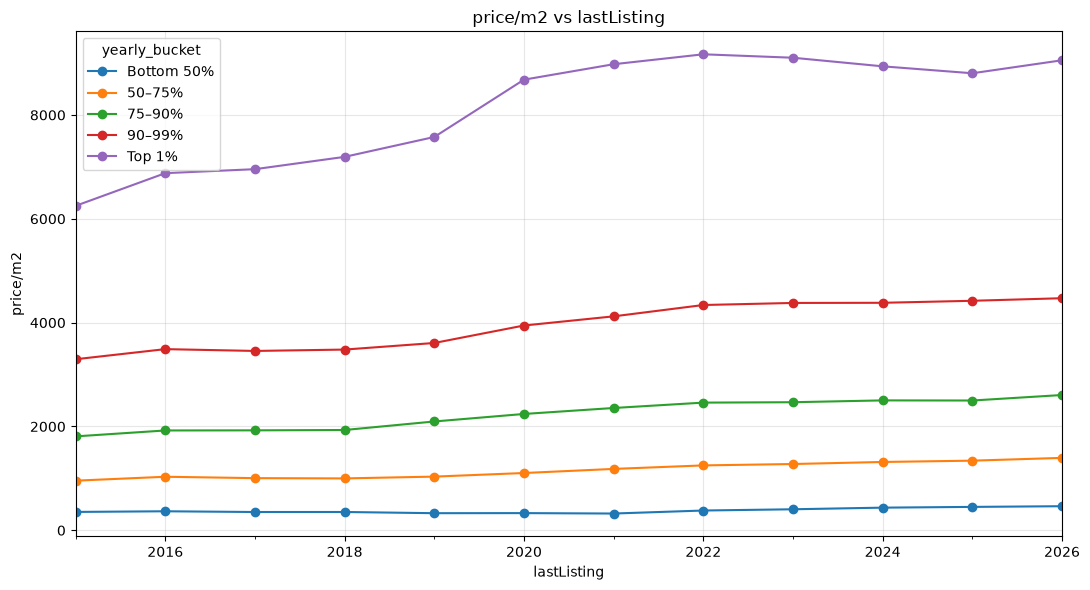

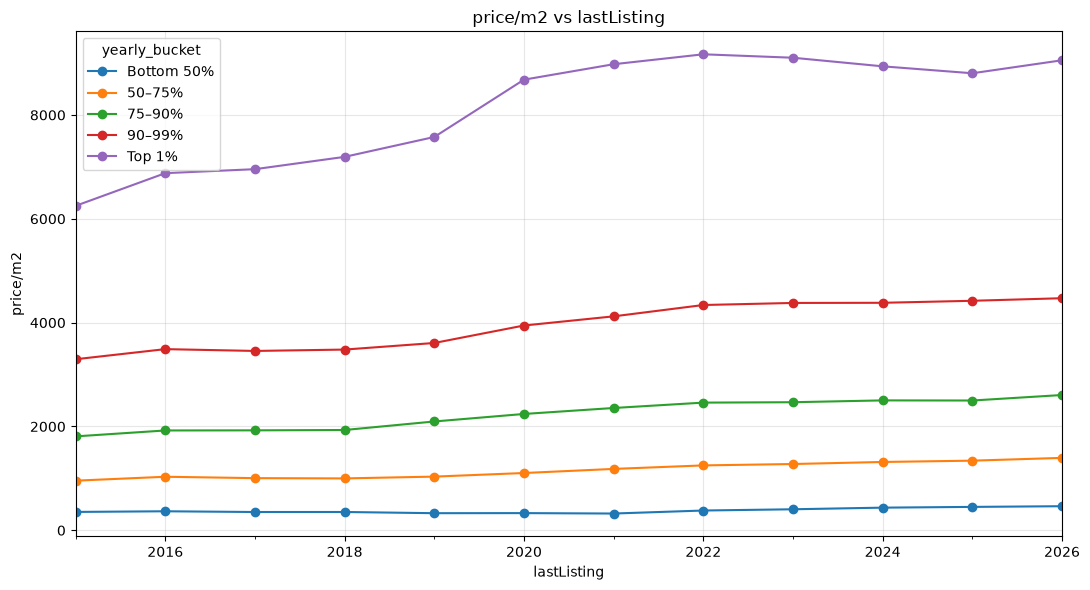

In [19]:
plot_data(
    data=data_realo,
    x="lastListing",
    y="price/m2",
    bucket_col = "price/m2",
    split_by=["yearly_bucket"],
    bucket_by_year=True,
    bucket_percentiles=[0.50, 0.75, 0.90, 0.99, 1.0],
    bucket_labels=[
        "Bottom 50%",
        "50–75%",
        "75–90%",
        "90–99%",
        "Top 1%",
    ],
    
    agg="median",
    #where={"housingType": "APARTMENT"},
    freq="YE",
)

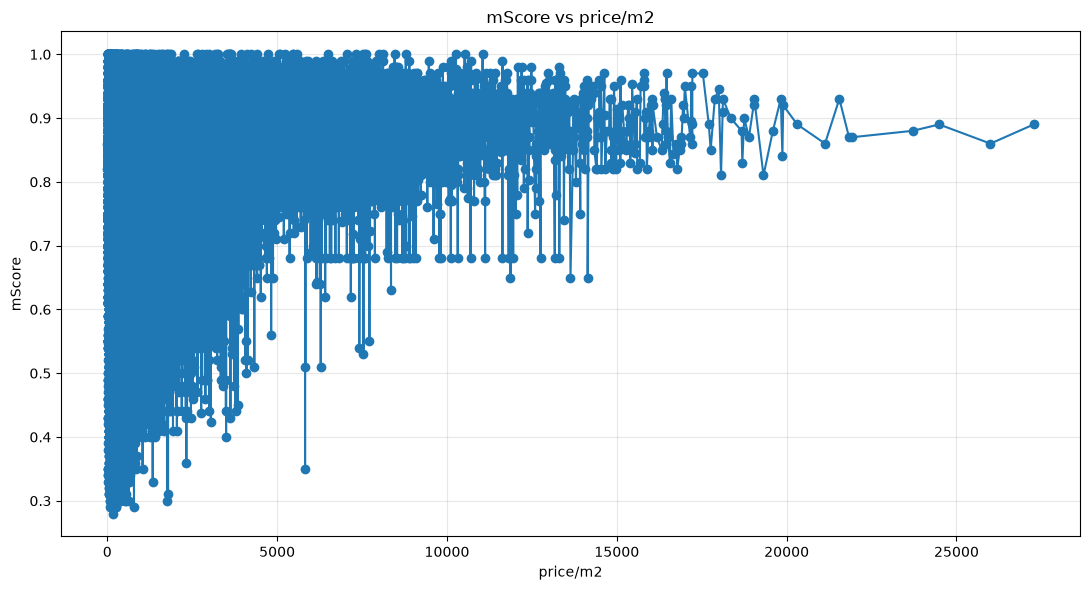

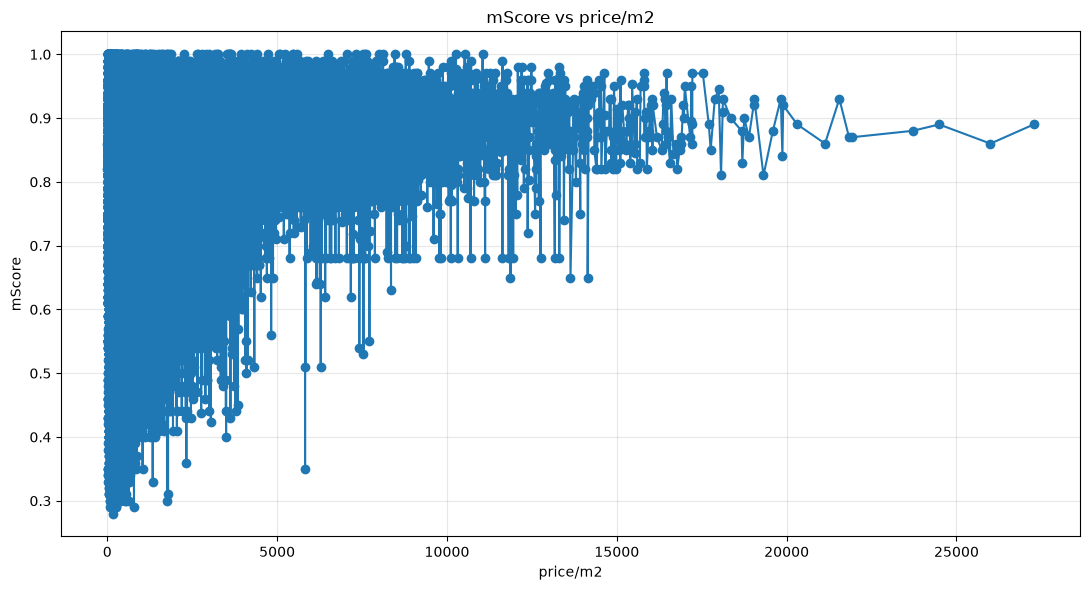

In [15]:
plot_data(
    data=data_realo,
    x="price/m2",
    y="mScore",
    bucket_col =None,
    split_by=None,
    bucket_by_year=False,
    bucket_percentiles=None,
    bucket_labels=[
        "Bottom 50%",
        "50–75%",
        "75–90%",
        "90–99%",
        "Top 1%",
    ]

)

In [16]:
data_realo.columns

Index(['addressId', 'admin1Id', 'admin1', 'admin2Id', 'admin2', 'localityId',
       'locality', 'subLocalityId', 'subLocality', 'districtId', 'district',
       'postalCode', 'niscode', 'region', 'lon', 'lat', 'addressType',
       'firstListing', 'lastListing', 'housingType', 'secondaryHousingType',
       'detachment', 'numberOfSides', 'price', 'initialPrice', 'way',
       'isPublicSale', 'habitableArea', 'terraceArea', 'buildingArea',
       'estimatedArea', 'hasGarden', 'estimatedGardenArea', 'isNewBuild',
       'buildYear', 'renovationYear', 'energyConsumption', 'certificateDate',
       'eLevel', 'kLevel', 'heatingType', 'floodProneLocation',
       'numberOfBedrooms', 'numberOfBathrooms', 'numberOfToilets',
       'numberOfFloors', 'floor', 'distanceToNearestCenter', 'busStopDistance',
       'trainStopDistance', 'schoolDistance', 'mScore', 'greenCoverage',
       'buildingCondition', 'cadastralIncome', 'hasSingleGlass',
       'hasDoubleGlass', 'hasSolarPanels', 'hasSwimming

In [17]:
plot_data(
    data_prices,
    x="lastListing",
    y="price",
    split_by = "price/m2",
    agg="median",
    freq="YE",
    title="Median listing price over time",
)

NameError: name 'data_prices' is not defined

In [ ]:
data_prices.groupby("price/m2")["price/m2"].transform(
                lambda s: s.pct_change() * 100
            )

KeyboardInterrupt: 

In [ ]:
data_realo['firstListing year_month']

0         2015-01
1         2015-01
2         2015-01
3         2015-01
4         2015-01
           ...   
540337    2026-05
540338    2026-05
540339    2024-05
540340    2024-07
540341    2025-07
Name: firstListing year_month, Length: 540340, dtype: period[M]

In [ ]:
data_prices = data_realo.copy()
data_prices = data_prices[data_prices["estimatedArea"]!= np.nan]
data_prices["price/m2"] = data_prices["price"] / data_prices["estimatedArea"]

In [ ]:
data_prices_extreme = data_prices[data_prices["price/m2"] >20000]
data_prices_extreme_bxlout = data_prices_extreme[data_prices_extreme["admin1"] != "Région de Bruxelles-Capitale"]

In [ ]:
data_prices_extreme

,addressId,admin1Id,admin1,admin2Id,admin2,localityId,locality,subLocalityId,subLocality,districtId,...,hasSolarPanels,hasSwimmingPool,hasCentralHeating,hasSolarBoiler,marker,ln(price),ln(initialPrice),firstListing year_month,lastListing year_month,price/m2
188169,5444249,5961077,Région de Bruxelles-Capitale,5389054,Bruxelles-Capitale,5388294,Uccle,5194020,Uccle,5199178,...,False,<NA>,<NA>,<NA>,POINT (4.3693404812552 50.809509737512),14.018859,14.018859,2026-03,2026-06,21129.310345
192876,5444249,5961077,Région de Bruxelles-Capitale,5389054,Bruxelles-Capitale,5388294,Uccle,5194020,Uccle,5199178,...,False,<NA>,<NA>,<NA>,POINT (4.3693404812552 50.809509737512),14.018859,14.018859,2026-06,NaT,21129.310345
281206,49733,5961077,Région de Bruxelles-Capitale,5389054,Bruxelles-Capitale,5387860,Bruxelles,5194008,Bruxelles,5198731,...,False,<NA>,<NA>,<NA>,POINT (4.3521502384345 50.848006679067),13.883169,13.883169,2016-11,2017-02,21836.734694
349885,67785,5961077,Région de Bruxelles-Capitale,5389054,Bruxelles-Capitale,5387860,Bruxelles,5194008,Bruxelles,5198749,...,False,<NA>,<NA>,False,POINT (4.3471503897115 50.850806251151),13.997832,13.997832,2020-06,2020-07,27272.727273
358288,4296505,5388851,Oost-Vlaanderen,5389061,Gent,5387960,Gent,5194766,Gent,5205168,...,False,<NA>,<NA>,False,POINT (3.723131927651 51.043837395267),14.133964,14.133964,2020-11,2021-01,23706.896552
361011,4296505,5388851,Oost-Vlaanderen,5389061,Gent,5387960,Gent,5194766,Gent,5205168,...,False,<NA>,<NA>,<NA>,POINT (3.723131927651 51.043837395267),14.133964,14.133964,2021-01,2021-04,23706.896552
362403,77223,5961077,Région de Bruxelles-Capitale,5389054,Bruxelles-Capitale,5387928,Etterbeek,5194009,Etterbeek,5198846,...,False,<NA>,<NA>,False,POINT (4.4001441893938 50.830834150369),14.038654,14.038654,2021-02,2021-07,21551.724138
386679,69758,5961077,Région de Bruxelles-Capitale,5389054,Bruxelles-Capitale,5387860,Bruxelles,5194008,Bruxelles,5198731,...,False,<NA>,False,False,POINT (4.3508674404556 50.847151242012),14.077875,14.077875,2022-05,2023-02,26000.0
408672,4363326,5388851,Oost-Vlaanderen,5389061,Gent,5387960,Gent,5194766,Gent,5205156,...,False,<NA>,False,False,POINT (3.7219240273324 51.04989344163),13.790193,13.790193,2023-04,2023-08,20312.5
416124,4363326,5388851,Oost-Vlaanderen,5389061,Gent,5387960,Gent,5194766,Gent,5205156,...,False,<NA>,<NA>,<NA>,POINT (3.7219240273324 51.04989344163),13.790193,13.790193,2023-08,2024-04,20312.5


In [ ]:
data_realo

,addressId,admin1Id,admin1,admin2Id,admin2,localityId,locality,subLocalityId,subLocality,districtId,...,hasDoubleGlass,hasSolarPanels,hasSwimmingPool,hasCentralHeating,hasSolarBoiler,marker,ln(price),ln(initialPrice),firstListing year_month,lastListing year_month
0,5388250,5961077,Région de Bruxelles-Capitale,5389054,Bruxelles-Capitale,5388250,Woluwe-Saint-Lambert,<NA>,<NA>,<NA>,...,<NA>,False,True,<NA>,<NA>,POINT (4.4346752599974 50.848389622058),12.936034,12.936034,2015-01,2015-04
1,4148489,5388851,Oost-Vlaanderen,5389060,Eeklo,5387914,Eeklo,5194725,Eeklo,5204854,...,<NA>,False,<NA>,<NA>,<NA>,POINT (3.56867938325 51.18208986125),12.128111,12.128111,2015-01,2015-02
2,4382733,5388851,Oost-Vlaanderen,5389061,Gent,5387960,Gent,5194766,Gent,5205161,...,<NA>,False,<NA>,<NA>,<NA>,POINT (3.7427086067292 51.044916495756),12.301383,12.301383,2015-01,2015-02
3,5388234,5961077,Région de Bruxelles-Capitale,5389054,Bruxelles-Capitale,5388234,Schaerbeek,<NA>,<NA>,<NA>,...,<NA>,False,<NA>,<NA>,<NA>,POINT (4.3800078727729 50.862264640847),12.945626,12.945626,2015-01,2015-02
4,196796,5961077,Région de Bruxelles-Capitale,5389054,Bruxelles-Capitale,5388250,Woluwe-Saint-Lambert,5194022,Woluwe-Saint-Lambert,5199284,...,<NA>,False,<NA>,<NA>,<NA>,POINT (4.4271738461231 50.851119165012),12.604849,12.604849,2015-01,2015-04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
540337,5760104,5388851,Oost-Vlaanderen,5389061,Gent,5388357,Zulte,<NA>,<NA>,<NA>,...,<NA>,False,<NA>,<NA>,<NA>,POINT (3.4662711019547 50.937620877048),12.771386,12.771386,2026-05,NaT
540338,5760104,5388851,Oost-Vlaanderen,5389061,Gent,5388357,Zulte,<NA>,<NA>,<NA>,...,<NA>,False,<NA>,<NA>,<NA>,POINT (3.4662711019547 50.937620877048),12.84661,12.84,2026-05,NaT
540339,5760119,5388851,Oost-Vlaanderen,5389060,Eeklo,5387797,Assenede,<NA>,<NA>,<NA>,...,<NA>,False,False,False,<NA>,POINT (3.6825490596406 51.219936384219),13.629181,13.629181,2024-05,2024-07
540340,5760119,5388851,Oost-Vlaanderen,5389060,Eeklo,5387797,Assenede,<NA>,<NA>,<NA>,...,<NA>,False,False,False,<NA>,POINT (3.6825490596406 51.219936384219),13.629181,13.629181,2024-07,2024-09


,admin2,Year,Median listing price,House price change (%),CPI inflation (%),Difference (percentage points)
0,Aalst,2016,235000.0,4.44,1.97,2.47
1,Aalst,2017,243000.0,3.4,2.13,1.28
2,Aalst,2018,245000.0,0.82,2.05,-1.23
3,Aalst,2019,249000.0,1.63,1.44,0.2
4,Aalst,2020,269000.0,8.03,0.74,7.29
...,...,...,...,...,...,...
65,Sint-Niklaas,2021,299000.0,1.7,2.44,-0.74
66,Sint-Niklaas,2022,324000.0,8.36,9.60,-1.24
67,Sint-Niklaas,2023,340000.0,4.94,4.05,0.89
68,Sint-Niklaas,2024,359000.0,5.59,3.14,2.44


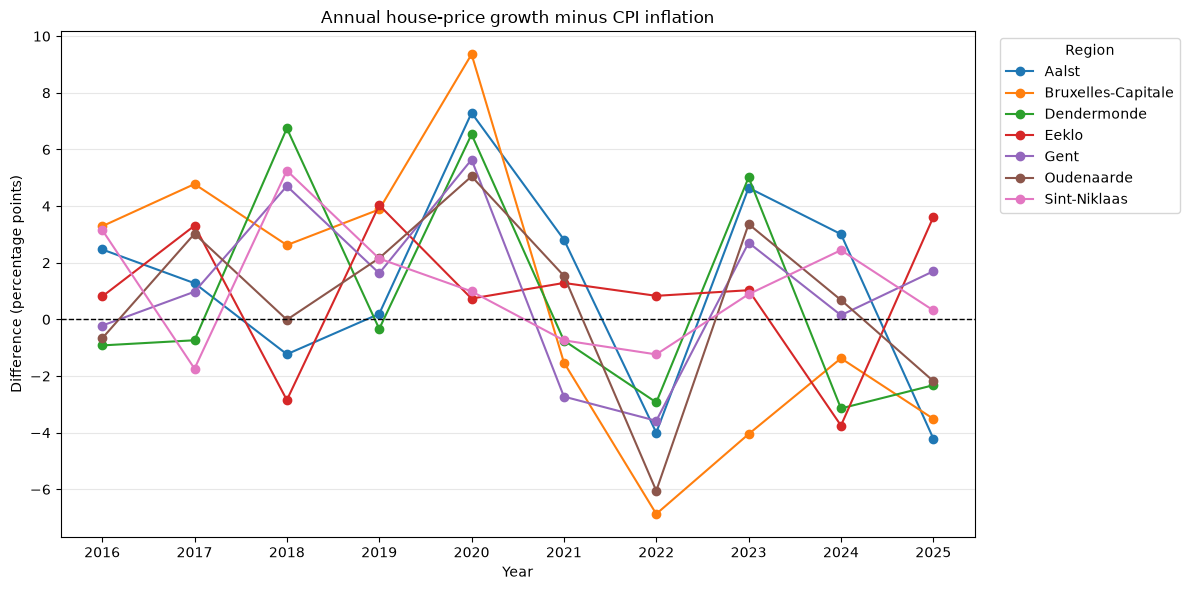

In [ ]:
# ---------------------------------------------------------------------------
# 6. Compare annual house-price growth with CPI inflation
# ---------------------------------------------------------------------------

from IPython.display import display


def plot_annual_house_price_cpi_difference(data_prices=data_realo,
                                           data_CPI=data_CPI,
                                           start_year=None,
                                           end_year=None):
    """Display annual house-price growth, CPI inflation, and their difference.

    House prices are annual median listing prices per region. CPI is the
    annual average of the monthly CPI index. The difference is measured in
    percentage points.
    Incomplete current years are excluded unless an end_year is provided.
    """
    required_price_columns = {'admin2', 'housingType', 'lastListing', 'price'}
    required_cpi_columns = {'Date', 'CPI index'}
    missing_price_columns = required_price_columns.difference(data_prices.columns)
    missing_cpi_columns = required_cpi_columns.difference(data_CPI.columns)
    if missing_price_columns or missing_cpi_columns:
        raise ValueError(
            f'Missing required columns: prices={sorted(missing_price_columns)}, '
            f'CPI={sorted(missing_cpi_columns)}'
        )

    prices = data_prices.copy()
    cpi = data_CPI.copy()
    prices['lastListing'] = pd.to_datetime(prices['lastListing'], errors='coerce')
    prices['price'] = pd.to_numeric(prices['price'], errors='coerce')
    prices = prices.dropna(subset=['admin2', 'housingType', 'lastListing', 'price'])
    prices = prices[prices['housingType'].astype(str).str.upper() == 'HOUSE']
    prices['Year'] = prices['lastListing'].dt.year

    if not pd.api.types.is_datetime64_any_dtype(cpi['Date']):
        cpi['Date'] = pd.to_datetime(cpi['Date'].astype(str),
                                     format='%m/%Y', errors='coerce')
    cpi['CPI index'] = pd.to_numeric(cpi['CPI index'], errors='coerce')
    cpi = cpi.dropna(subset=['Date', 'CPI index'])
    cpi['Year'] = cpi['Date'].dt.year
    if prices.empty or cpi.empty:
        raise ValueError('Both house-price and CPI data must contain valid observations.')

    latest_price_date = prices['lastListing'].max()
    latest_cpi_date = cpi['Date'].max()
    latest_complete_year = min(
        latest_price_date.year if latest_price_date.month == 12 else latest_price_date.year - 1,
        latest_cpi_date.year if latest_cpi_date.month == 12 else latest_cpi_date.year - 1,
    )
    first_year = int(start_year) if start_year is not None else int(
        max(prices['Year'].min(), cpi['Year'].min())
    )
    last_year = int(end_year) if end_year is not None else latest_complete_year
    if first_year > last_year:
        raise ValueError('start_year must be less than or equal to end_year.')

    annual_prices = (prices.groupby(['admin2', 'Year'])['price']
                     .median().rename('Median listing price').reset_index())
    annual_prices = annual_prices.sort_values(['admin2', 'Year'])
    annual_prices['House price change (%)'] = (
        annual_prices.groupby('admin2')['Median listing price']
        .pct_change(fill_method=None) * 100
    )
    previous_price_year = annual_prices.groupby('admin2')['Year'].shift()
    annual_prices.loc[
        previous_price_year != annual_prices['Year'] - 1,
        'House price change (%)'
    ] = float('nan')

    annual_cpi = (cpi.groupby('Year')['CPI index'].mean()
                  .rename('Annual average CPI').reset_index().sort_values('Year'))
    annual_cpi['CPI inflation (%)'] = (
        annual_cpi['Annual average CPI'].pct_change(fill_method=None) * 100
    )
    previous_cpi_year = annual_cpi['Year'].shift()
    annual_cpi.loc[
        previous_cpi_year != annual_cpi['Year'] - 1,
        'CPI inflation (%)'
    ] = float('nan')

    annual_comparison = annual_prices.merge(
        annual_cpi[['Year', 'CPI inflation (%)']], on='Year', how='left'
    )
    annual_comparison['Difference (percentage points)'] = (
        annual_comparison['House price change (%)']
        - annual_comparison['CPI inflation (%)']
    )
    annual_comparison = annual_comparison[
        annual_comparison['Year'].between(first_year, last_year)
    ].dropna(subset=['House price change (%)', 'CPI inflation (%)'])
    annual_comparison = annual_comparison.reset_index(drop=True)
    if annual_comparison.empty:
        raise ValueError(
            'No complete year-over-year comparisons are available for the selected year range.'
        )

    display(annual_comparison.round(2))
    fig, ax = plt.subplots(figsize=(12, 6))
    for region, region_data in annual_comparison.groupby('admin2'):
        ax.plot(region_data['Year'],
                region_data['Difference (percentage points)'],
                marker='o', linewidth=1.5, label=region)
    ax.axhline(0, color='black', linewidth=1, linestyle='--')
    ax.set_title('Annual house-price growth minus CPI inflation')
    ax.set_xlabel('Year')
    ax.set_ylabel('Difference (percentage points)')
    ax.set_xticks(sorted(annual_comparison['Year'].unique()))
    ax.legend(title='Region', bbox_to_anchor=(1.02, 1), loc='upper left')
    ax.grid(axis='y', alpha=0.3)
    fig.tight_layout()
    plt.show()
    return annual_comparison


annual_house_cpi_difference = plot_annual_house_price_cpi_difference()
